# Bitcoin forecasting benchmark: directional accuracy under three definitions (v19)

Companion notebook for the manuscript. It compares nine one-day-ahead forecasts of the
Bitcoin daily close over 1 January 2024 to 11 November 2026 under one protocol. Every model
is tested against the random walk, and directional accuracy is computed in three ways: on the
traded signal, on the change between consecutive price
forecasts, and on the change between consecutive return forecasts. Forecasts that use no
model (a constant price, the lagged price, a momentum rule, moving averages) are scored in
the same way. Trading results are reported in excess of the Treasury-bill rate together with
their sampling uncertainty. Price-target models use the 19 features of the feature file;
return-target models use 13 stationary transformations of them (Section 2), and Section 9
refits them on the 19 features as a check.

**Inputs** (not redistributed; see `data/README.md` and `raw/README.md`)
- `data/btc_features_2017-01-01_2026-11-12_no_trends.csv`: 19 price-based features and
  the next-day close, built from the CoinMarketCap exports with
  `python scripts/prepare_raw.py --indir raw/cmc_exports --end 2026-11-12` and
  `python scripts/build_features.py --ohlcv raw/btc_ohlcv_2017-01-01_2026-11-12.csv`.
- `raw/fred_tb3ms.csv`: 3-month Treasury bill rate, monthly averages
  (FRED series TB3MS, https://fred.stlouisfed.org/series/TB3MS).

**Outputs**: tables in `results/v19/`, figures in `figures/v19/`. Forecasts in price
units go to `results/v19/_local/`, which is never published because it contains
vendor prices.

**Run time**: about 30 minutes on two CPU cores, of which about 15 for the 100-epoch check
of Section 8 and about 5 for the simulations of Sections 5, 10 and 11.

**Quick check**: set the environment variable `BTC_FAST=1` to run with 3 epochs, one
seed and few bootstrap and Monte Carlo draws. Its numbers are not the reported ones.

## 1. Setup

In [1]:
import os, time, json, random, hashlib, platform, warnings
from pathlib import Path
from itertools import product

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.ticker
import matplotlib.dates
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.multitest import multipletests
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
import arch
from arch.bootstrap import MCS
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Dropout, LSTM, GRU, Dense, Layer
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import tensorflow.keras.backend as K

T0_NOTEBOOK = time.time()
FAST = os.environ.get('BTC_FAST', '0') == '1'

# ---- design ---------------------------------------------------------------
TRAIN_END, VAL_END = '2022-12-31', '2023-12-31'   # test: 2024-01-01 to the last forecast date
SEEDS = [42] if FAST else [42, 123, 456]
LOOKBACK = 30                                     # days in each deep-learning input window
MAX_EPOCHS = 3 if FAST else 100
PATIENCE = 10                                     # early stopping on the validation loss
DL_GRID = [(1e-3, 32)] if FAST else [(1e-3, 32), (1e-3, 64), (3e-4, 32), (3e-4, 64)]  # (learning rate, batch)
COSTS_BP = [0, 10, 25, 50]                        # transaction cost per side, basis points
BLOCK = 10                                        # block length for the bootstraps (about T**(1/3))
N_BOOT = 200 if FAST else 2000                    # Sharpe-difference bootstrap draws
MCS_REPS = 200 if FAST else 5000                  # model confidence set bootstrap draws
MC_REPS = 400 if FAST else 100000                 # Monte Carlo replications
MC_CHUNK = 2000                                   # replications simulated at a time
N_PATHS = 4000 if FAST else 1000000               # resampled paths for the calibrated directional tests
N_SIM = 4000 if FAST else 200000                  # paths of the level-rule simulation and of the block-length check
BLOCKS_CAL = [1, 5, 10, 20, 30, 50]               # block lengths compared for the calibrated tests
TIE = 1e-12                                       # two consecutive forecasts closer than this are equal
N_CI = 200 if FAST else 5000                      # bootstrap draws for the correlation intervals
DM_LAGS = [30, 100, 300]                          # longer truncation lags for the Diebold-Mariano check
ANN = 365                                         # Bitcoin trades every calendar day

print(f'FAST mode: {FAST} | seeds: {SEEDS} | max epochs: {MAX_EPOCHS}')


def set_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


tf.config.experimental.enable_op_determinism()
set_seeds(42)

# ---- paths ------------------------------------------------------------------
_env = os.environ.get('BTC_BENCHMARK_ROOT')
_here = Path.cwd().resolve()
ROOT = Path(_env).expanduser().resolve() if _env else (_here.parent if _here.name == 'notebooks' else _here)
FEATURES_CSV = ROOT / 'data' / 'btc_features_2017-01-01_2026-11-12_no_trends.csv'
RF_CSV = ROOT / 'raw' / 'fred_tb3ms.csv'
RES = ROOT / 'results' / 'v19'
LOCAL = RES / '_local'          # forecasts in price units: never published
FIG = ROOT / 'figures' / 'v19'
for d in (RES, LOCAL, FIG):
    d.mkdir(parents=True, exist_ok=True)
for p in (FEATURES_CSV, RF_CSV):
    print(f'{"found  " if p.exists() else "MISSING"} {p.relative_to(ROOT).as_posix()}')

plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
                     'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8,
                     'legend.fontsize': 7, 'xtick.labelsize': 7, 'ytick.labelsize': 7})
FIG_W = 5.2   # inches: single-column width
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scipy': scipy.__version__, 'statsmodels': statsmodels.__version__,
            'scikit-learn': sklearn.__version__, 'xgboost': xgb.__version__,
            'tensorflow': tf.__version__, 'arch': arch.__version__,
            'matplotlib': matplotlib.__version__, 'platform': platform.platform()}
for k, v in VERSIONS.items():
    print(f'  {k:13s} {v}')

FAST mode: False | seeds: [42, 123, 456] | max epochs: 100
found   data/btc_features_2017-01-01_2026-11-12_no_trends.csv
found   raw/fred_tb3ms.csv
  python        3.11.18
  numpy         1.26.4
  pandas        2.2.2
  scipy         1.13.0
  statsmodels   0.14.2
  scikit-learn  1.5.0
  xgboost       2.0.3
  tensorflow    2.16.1
  arch          7.2.0
  matplotlib    3.8.4
  platform      Linux-6.18.44-fc-v653-x86_64-with-glibc2.39


## 2. Data

The feature file holds one row per day: the OHLCV values of day *t*, 19 features computed
from data up to day *t*, and the close of day *t*+1 (`target_price`). The next-day log
return is derived here. The fingerprint printed below lets a reader confirm that a
rebuilt file is the one used for every number in the manuscript.

In [2]:
df = pd.read_csv(FEATURES_CSV, parse_dates=['date']).set_index('date').sort_index()
FEATURES = ['open', 'high', 'low', 'close', 'volume', 'market_cap', 'log_return',
            'volatility_7d', 'volatility_30d', 'rsi_14', 'ema_7', 'ema_30', 'macd',
            'macd_signal', 'bb_upper', 'bb_lower', 'bb_width', 'high_low_ratio',
            'close_open_ratio']
assert list(df.columns) == FEATURES + ['target_price', 'target_direction'], df.columns.tolist()
assert df.notna().all().all()
assert (df.index.to_series().diff().dropna() == pd.Timedelta('1D')).all(), 'missing days'
df['target_ret'] = np.log(df['target_price'] / df['close'])      # log(P_{t+1} / P_t)

FINGERPRINT = {'rows': len(df), 'first': str(df.index.min().date()), 'last': str(df.index.max().date())}
for c in ['close', 'log_return', 'volatility_7d', 'rsi_14', 'volume']:
    FINGERPRINT[c] = {'mean': float(df[c].mean()), 'std': float(df[c].std()),
                      'min': float(df[c].min()), 'max': float(df[c].max())}
print(f'{len(df)} rows, {FINGERPRINT["first"]} to {FINGERPRINT["last"]}, {len(FEATURES)} features')
print(json.dumps(FINGERPRINT, indent=1))

3572 rows, 2017-01-31 to 2026-11-11, 19 features
{
 "rows": 3572,
 "first": "2017-01-31",
 "last": "2026-11-11",
 "close": {
  "mean": 37425.43023236282,
  "std": 32847.99024378759,
  "min": 937.52,
  "max": 124752.53
 },
 "log_return": {
  "mean": 0.0012280384920232397,
  "std": 0.03516287074777355,
  "min": -0.4647297680590224,
  "max": 0.2251189979873116
 },
 "volatility_7d": {
  "mean": 0.029698519134103367,
  "std": 0.018610810428490793,
  "min": 0.0019983307404368,
  "max": 0.1902841401882699
 },
 "rsi_14": {
  "mean": 53.04010251060958,
  "std": 18.249013859655715,
  "min": 4.699029586921967,
  "max": 99.76562792965088
 },
 "volume": {
  "mean": 27941674833.874485,
  "std": 22031702982.19834,
  "min": 67530000.0,
  "max": 350967941479.06
 }
}


### Risk-free rate

The monthly average of the 3-month Treasury bill rate (discount basis, % per year) is
applied to every calendar day of its month and converted to a daily rate over 365 days.
The last published month is carried forward to the following days.

In [3]:
tb = pd.read_csv(RF_CSV, parse_dates=['observation_date']).set_index('observation_date')['TB3MS']
month = df.index.to_period('M').to_timestamp()
rf_annual = tb.reindex(tb.index.union(month.unique())).ffill().reindex(month).values / 100
df['rf'] = (1 + rf_annual) ** (1 / ANN) - 1
print(f'TB3MS from {tb.index.min():%Y-%m} to {tb.index.max():%Y-%m}; '
      f'{int((month > tb.index.max()).sum())} days after the last month use its value')

TB3MS from 2016-12 to 2026-10; 11 days after the last month use its value


### Chronological split

Training 2017-01-31 to 2022-12-31, validation 2023, test 2024-01-01 onwards. The tuned
hyperparameters are chosen on the validation year; the selected models are then refitted
on training plus validation and evaluated once on the test period.

Twelve of the 19 features are price or volume levels, or move with the price level
(open, high, low, close, volume, market capitalisation, the two moving averages, the
MACD line and its signal, the two Bollinger bands). The return-target models use 13
stationary transformations instead: the log return, the two volatilities, the RSI, the
Bollinger width, the high/low and close/open ratios, the close relative to each moving
average, the MACD line and its signal divided by the close, the position of the close
between the Bollinger bands, and the daily log change of volume. Both feature sets are
standardised with the means and standard deviations of the training years.

In [4]:
df['close_ema_7'] = df['close'] / df['ema_7'] - 1
df['close_ema_30'] = df['close'] / df['ema_30'] - 1
df['macd_close'] = df['macd'] / df['close']
df['macd_signal_close'] = df['macd_signal'] / df['close']
df['bb_position'] = (df['close'] - df['bb_lower']) / (df['bb_upper'] - df['bb_lower'])
df['volume_change'] = np.log(df['volume'] / df['volume'].shift(1)).fillna(0.0)   # first day: no previous volume
STAT_FEATURES = ['log_return', 'volatility_7d', 'volatility_30d', 'rsi_14', 'bb_width', 'high_low_ratio',
                 'close_open_ratio', 'close_ema_7', 'close_ema_30', 'macd_close', 'macd_signal_close',
                 'bb_position', 'volume_change']

bounds = {'train': (df.index.min(), pd.Timestamp(TRAIN_END)),
          'validation': (pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1), pd.Timestamp(VAL_END)),
          'test': (pd.Timestamp(VAL_END) + pd.Timedelta(days=1), df.index.max())}
part = {k: df.loc[a:b] for k, (a, b) in bounds.items()}
rows = []
for k, d in part.items():
    rows.append({'split': k, 'first forecast date': d.index.min().date(), 'last forecast date': d.index.max().date(),
                 'days': len(d), 'mean close ($)': d['close'].mean(), 'min close ($)': d['close'].min(),
                 'max close ($)': d['close'].max(), 'sd of daily log return': d['target_ret'].std(),
                 'up days (%)': 100 * (d['target_ret'] > 0).mean(),
                 'T-bill rate (% a year)': 100 * ((1 + d['rf']).prod() ** (ANN / len(d)) - 1)})
t_split = pd.DataFrame(rows)
t_split.to_csv(RES / 't01_splits.csv', index=False)
print(t_split.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

stationarity = []
for label, series in [('close', df['close']), ('daily log return', df['target_ret'])]:
    stationarity.append({'series': label, 'ADF p': adfuller(series, autolag='AIC')[1],
                         'KPSS p': kpss(series, regression='c', nlags='auto')[1]})
t_stat = pd.DataFrame(stationarity)
t_stat.to_csv(RES / 't01b_stationarity.csv', index=False)
print(t_stat.to_string(index=False))

n_tr, n_va, n_te = (len(part[k]) for k in ('train', 'validation', 'test'))
i_tr = np.arange(0, n_tr)
i_va = np.arange(n_tr, n_tr + n_va)
i_te = np.arange(n_tr + n_va, len(df))
i_trva = np.concatenate([i_tr, i_va])
scaler = StandardScaler().fit(df[FEATURES].values[i_tr])      # fitted on the training years only
X_all = scaler.transform(df[FEATURES].values)
scaler_stat = StandardScaler().fit(df[STAT_FEATURES].values[i_tr])
X_stat = scaler_stat.transform(df[STAT_FEATURES].values)
X_BY_TARGET = {'price': X_all, 'return': X_stat}

rows = []
for f in FEATURES + [c for c in STAT_FEATURES if c not in FEATURES]:
    v, hi, lo = df[f].values, df[f].values[i_trva].max(), df[f].values[i_trva].min()
    rows.append({'feature': f, 'set': 'level' if f not in STAT_FEATURES else 'stationary',
                 'test days above the 2017-2023 maximum (%)': 100 * np.mean(v[i_te] > hi),
                 'test days below the 2017-2023 minimum (%)': 100 * np.mean(v[i_te] < lo)})
t_range = pd.DataFrame(rows)
t_range.to_csv(RES / 't01c_feature_range.csv', index=False)
print(t_range.to_string(index=False, float_format=lambda v: f'{v:,.1f}'))
P = df['close'].values                 # P_t: close on the forecast date
P_next = df['target_price'].values     # P_{t+1}: the close being forecast
R_next = df['target_ret'].values       # log(P_{t+1} / P_t)
TARGETS = {'price': P_next, 'return': R_next}
test_dates = df.index[i_te]
print(f'forecasts: train {n_tr}, validation {n_va}, test {n_te}')

     split first forecast date last forecast date  days  mean close ($)  min close ($)  max close ($)  sd of daily log return  up days (%)  T-bill rate (% a year)
     train          2017-01-31         2022-12-31  2161     17,848.8004       937.5200    67,566.8300                  0.0408      52.8459                  1.2324
validation          2023-01-01         2023-12-31   365     28,859.4728    16,625.0800    44,166.6000                  0.0228      49.8630                  5.0703
      test          2024-01-01         2026-11-11  1046     80,859.1507    39,507.3700   124,752.5300                  0.0246      50.0956                  4.2754


          series    ADF p  KPSS p
           close 0.650583    0.01
daily log return 0.000000    0.10


          feature        set  test days above the 2017-2023 maximum (%)  test days below the 2017-2023 minimum (%)
             open      level                                       67.5                                        0.0
             high      level                                       67.3                                        0.0
              low      level                                       66.6                                        0.0
            close      level                                       67.5                                        0.0
           volume      level                                        0.0                                        0.0
       market_cap      level                                       78.3                                        0.0
       log_return stationary                                        0.0                                        0.0
    volatility_7d stationary                                        0.0         

/tmp/ipykernel_1841/2728594087.py:29: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  'KPSS p': kpss(series, regression='c', nlags='auto')[1]})
/tmp/ipykernel_1841/2728594087.py:29: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  'KPSS p': kpss(series, regression='c', nlags='auto')[1]})


## 3. Forecasters

Nine forecasts of the next-day close $P_{t+1}$:

* **Random walk**: $\hat P_{t+1} = P_t$.
* Four learned models (random forest, XGBoost, CNN-LSTM, GRU with additive attention),
  each trained on two targets:
  * **price**: the model predicts $P_{t+1}$ directly, as in most of the literature;
  * **return**: the model predicts $r_{t+1} = \log(P_{t+1}/P_t)$ and
    $\hat P_{t+1} = P_t\,e^{\hat r_{t+1}}$.

Random forest and the deep models are run with three seeds and their forecasts averaged;
XGBoost is deterministic. Price-target models read the 19 features, return-target models
the 13 stationary ones.

In [5]:
forecasts = {'Random Walk': P[i_te].copy()}
forecasts_seed = {}     # model -> {seed: forecast}
fit_info = []
LEARNED = [f'{m}-{t}' for t in ('price', 'return') for m in ('RF', 'XGB', 'CNN-LSTM', 'GRU-Att')]
ORDER = ['Random Walk'] + LEARNED


def to_price(pred, target, rows):
    """Turn a forecast in target units into a forecast of P_{t+1}."""
    return pred if target == 'price' else P[rows] * np.exp(pred)


def val_mse(pred, target):
    return float(np.mean((pred - TARGETS[target][i_va]) ** 2))

In [6]:
# Random forest: 100 trees, sqrt(number of features) candidates per split (4 of 19, 3 of 13)
RF_GRID = [(d, leaf) for d in (5, 10, 20) for leaf in (1, 5)]


def fit_rf(target, depth, leaf, seed, rows, X):
    m = RandomForestRegressor(n_estimators=100, max_depth=depth, min_samples_leaf=leaf,
                              max_features='sqrt', random_state=seed, n_jobs=-1)
    return m.fit(X[rows], TARGETS[target][rows])


for target in ('price', 'return'):
    t0 = time.time()
    X = X_BY_TARGET[target]
    losses_val = [val_mse(fit_rf(target, d, leaf, 42, i_tr, X).predict(X[i_va]), target) for d, leaf in RF_GRID]
    depth, leaf = RF_GRID[int(np.argmin(losses_val))]
    name = f'RF-{target}'
    forecasts_seed[name] = {s: to_price(fit_rf(target, depth, leaf, s, i_trva, X).predict(X[i_te]), target, i_te)
                            for s in SEEDS}
    forecasts[name] = np.mean(list(forecasts_seed[name].values()), axis=0)
    fit_info.append({'model': name, 'selected': f'max_depth={depth}, min_samples_leaf={leaf}',
                     'configurations tried': len(RF_GRID), 'parameters': None, 'seconds': time.time() - t0})
    print(f'{name}: max_depth={depth}, min_samples_leaf={leaf}  ({time.time() - t0:.0f}s)')

RF-price: max_depth=10, min_samples_leaf=5  (4s)


RF-return: max_depth=5, min_samples_leaf=1  (4s)


In [7]:
# XGBoost: 27 configurations
XGB_GRID = list(product([0.05, 0.1, 0.2], [4, 6, 8], [200, 500, 1000]))   # learning rate, depth, trees


def fit_xgb(target, lr, depth, n, rows, X):
    m = xgb.XGBRegressor(learning_rate=lr, max_depth=depth, n_estimators=n,
                         random_state=42, n_jobs=-1, verbosity=0)
    return m.fit(X[rows], TARGETS[target][rows])


xgb_val = []
for target in ('price', 'return'):
    t0 = time.time()
    X = X_BY_TARGET[target]
    losses_val = [val_mse(fit_xgb(target, *g, i_tr, X).predict(X[i_va]), target) for g in XGB_GRID]
    xgb_val += [{'target': target, 'learning rate': g[0], 'max depth': g[1], 'trees': g[2],
                 'validation MSE': v} for g, v in zip(XGB_GRID, losses_val)]
    lr, depth, n = XGB_GRID[int(np.argmin(losses_val))]
    name = f'XGB-{target}'
    pred = to_price(fit_xgb(target, lr, depth, n, i_trva, X).predict(X[i_te]), target, i_te)
    forecasts_seed[name] = {s: pred for s in SEEDS}       # identical for every seed
    forecasts[name] = pred
    fit_info.append({'model': name, 'selected': f'learning_rate={lr}, max_depth={depth}, n_estimators={n}',
                     'configurations tried': len(XGB_GRID), 'parameters': None, 'seconds': time.time() - t0})
    print(f'{name}: learning_rate={lr}, max_depth={depth}, n_estimators={n}  ({time.time() - t0:.0f}s)')
pd.DataFrame(xgb_val).to_csv(RES / 't02a_xgb_validation.csv', index=False)

XGB-price: learning_rate=0.05, max_depth=4, n_estimators=200  (41s)


XGB-return: learning_rate=0.05, max_depth=4, n_estimators=200  (21s)


### Deep models

The input for forecast date *t* is the window of the 30 days ending on *t* itself, so the
most recent close is always seen. Configurations (learning rate, batch size) are compared
on the validation loss with early stopping (seed 42); the selected configuration is then
refitted on training plus validation for the number of epochs at which its validation
loss was lowest, once per seed.

In [8]:
class BahdanauAttention(Layer):
    """Additive attention over the GRU states."""
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.W = Dense(units)
        self.v = Dense(1)

    def call(self, h):
        alpha = tf.nn.softmax(self.v(tf.nn.tanh(self.W(h))), axis=1)
        return tf.reduce_sum(alpha * h, axis=1)


def build(arch_name, lr, n_features):
    K.clear_session()
    inp = Input(shape=(LOOKBACK, n_features))
    if arch_name == 'CNN-LSTM':
        x = Conv1D(64, 3, activation='relu')(inp)
        x = MaxPooling1D(2)(x)
        x = Dropout(0.2)(x)
        x = LSTM(50)(x)
        x = Dropout(0.2)(x)
    else:
        x = BahdanauAttention(64)(GRU(64, return_sequences=True)(inp))
    model = Model(inp, Dense(1)(x))
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    return model


def windows(rows, X):
    """Window of the LOOKBACK days ending on each forecast date t."""
    return np.stack([X[t - LOOKBACK + 1:t + 1] for t in rows])


r_tr = i_tr[LOOKBACK - 1:]                 # the first 29 training days have no full window
r_trva = np.concatenate([r_tr, i_va])
WIN = {t: {'tr': windows(r_tr, X), 'va': windows(i_va, X), 'trva': windows(r_trva, X), 'te': windows(i_te, X)}
       for t, X in X_BY_TARGET.items()}
y_scalers = {t: StandardScaler().fit(TARGETS[t][r_tr].reshape(-1, 1)) for t in TARGETS}


def ys(target, rows):
    return y_scalers[target].transform(TARGETS[target][rows].reshape(-1, 1)).ravel()


DL = [(a, t) for t in ('price', 'return') for a in ('CNN-LSTM', 'GRU-Att')]
for t, w in WIN.items():
    print(f'{t} target windows: train {w["tr"].shape}, validation {w["va"].shape}, test {w["te"].shape}')

price target windows: train (2132, 30, 19), validation (365, 30, 19), test (1046, 30, 19)
return target windows: train (2132, 30, 13), validation (365, 30, 13), test (1046, 30, 13)


In [9]:
dl_tuning = []
for arch_name, target in DL:
    for lr, batch in DL_GRID:
        set_seeds(42)
        t0 = time.time()
        w = WIN[target]
        m = build(arch_name, lr, w['tr'].shape[2])
        h = m.fit(w['tr'], ys(target, r_tr), validation_data=(w['va'], ys(target, i_va)),
                  epochs=MAX_EPOCHS, batch_size=batch, verbose=0,
                  callbacks=[EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)])
        vl = h.history['val_loss']
        dl_tuning.append({'model': f'{arch_name}-{target}', 'learning rate': lr, 'batch size': batch,
                          'best epoch': int(np.argmin(vl)) + 1, 'epochs run': len(vl),
                          'validation MSE (standardised)': float(np.min(vl)), 'seconds': time.time() - t0})
        print(f'{arch_name}-{target:6s} lr={lr:g} batch={batch}: best epoch {int(np.argmin(vl)) + 1:3d} '
              f'of {len(vl):3d}, validation MSE {np.min(vl):.4f}  ({time.time() - t0:.0f}s)')
t_dl_tuning = pd.DataFrame(dl_tuning)
t_dl_tuning.to_csv(RES / 't02b_dl_validation.csv', index=False)

CNN-LSTM-price  lr=0.001 batch=32: best epoch   1 of  11, validation MSE 0.0094  (9s)


CNN-LSTM-price  lr=0.001 batch=64: best epoch   2 of  12, validation MSE 0.0061  (8s)


CNN-LSTM-price  lr=0.0003 batch=32: best epoch   3 of  13, validation MSE 0.0049  (10s)


CNN-LSTM-price  lr=0.0003 batch=64: best epoch   4 of  14, validation MSE 0.0057  (9s)


GRU-Att-price  lr=0.001 batch=32: best epoch   1 of  11, validation MSE 0.0091  (15s)


GRU-Att-price  lr=0.001 batch=64: best epoch   2 of  12, validation MSE 0.0084  (14s)


... (6 outputs left out)

GRU-Att-return lr=0.001 batch=32: best epoch   3 of  13, validation MSE 0.3461  (17s)


GRU-Att-return lr=0.001 batch=64: best epoch   4 of  14, validation MSE 0.3164  (14s)


GRU-Att-return lr=0.0003 batch=32: best epoch   5 of  15, validation MSE 0.3233  (18s)


GRU-Att-return lr=0.0003 batch=64: best epoch   1 of  11, validation MSE 0.3184  (13s)


In [10]:
for arch_name, target in DL:
    name = f'{arch_name}-{target}'
    tun = t_dl_tuning[t_dl_tuning['model'] == name]
    best = tun.loc[tun['validation MSE (standardised)'].idxmin()]
    lr, batch, n_epochs = float(best['learning rate']), int(best['batch size']), int(best['best epoch'])
    forecasts_seed[name] = {}
    t0 = time.time()
    for seed in SEEDS:
        set_seeds(seed)
        w = WIN[target]
        m = build(arch_name, lr, w['trva'].shape[2])
        m.fit(w['trva'], ys(target, r_trva), epochs=n_epochs, batch_size=batch, verbose=0)
        pred = y_scalers[target].inverse_transform(m.predict(w['te'], verbose=0)).ravel().astype(np.float64)
        forecasts_seed[name][seed] = to_price(pred, target, i_te)
    forecasts[name] = np.mean(list(forecasts_seed[name].values()), axis=0)
    fit_info.append({'model': name, 'selected': f'learning_rate={lr:g}, batch={batch}, epochs={n_epochs}',
                     'configurations tried': len(DL_GRID), 'parameters': m.count_params(),
                     'seconds': time.time() - t0})
    print(f'{name}: learning_rate={lr:g}, batch={batch}, {n_epochs} epochs, '
          f'{m.count_params():,} parameters  ({time.time() - t0:.0f}s for {len(SEEDS)} seeds)')

t_fit = pd.DataFrame(fit_info).set_index('model').loc[LEARNED].reset_index()
t_fit.to_csv(RES / 't03_selected_configurations.csv', index=False)
print(t_fit.to_string(index=False))
pd.DataFrame({k: forecasts[k] for k in ORDER}, index=test_dates).to_csv(LOCAL / 'forecasts_test_price.csv')
for k in ORDER:
    assert np.all(np.isfinite(forecasts[k])) and np.all(forecasts[k] > 0), k

CNN-LSTM-price: learning_rate=0.0003, batch=32, 3 epochs, 26,763 parameters  (14s for 3 seeds)


GRU-Att-price: learning_rate=0.0003, batch=64, 6 epochs, 20,610 parameters  (31s for 3 seeds)


CNN-LSTM-return: learning_rate=0.001, batch=32, 1 epochs, 25,611 parameters  (11s for 3 seeds)


GRU-Att-return: learning_rate=0.001, batch=64, 4 epochs, 19,458 parameters  (23s for 3 seeds)
          model                                          selected  configurations tried  parameters   seconds
       RF-price                  max_depth=10, min_samples_leaf=5                     6         NaN  4.279095
      XGB-price learning_rate=0.05, max_depth=4, n_estimators=200                    27         NaN 41.491783
 CNN-LSTM-price          learning_rate=0.0003, batch=32, epochs=3                     4     26763.0 14.263533
  GRU-Att-price          learning_rate=0.0003, batch=64, epochs=6                     4     20610.0 31.202125
      RF-return                   max_depth=5, min_samples_leaf=1                     6         NaN  3.675900
     XGB-return learning_rate=0.05, max_depth=4, n_estimators=200                    27         NaN 20.528423
CNN-LSTM-return           learning_rate=0.001, batch=32, epochs=1                     4     25611.0 11.288104
 GRU-Att-return           

## 4. Accuracy against the random walk

Inference uses losses in return units, $(r_{t+1}-\hat r_{t+1})^2$ with
$\hat r_{t+1}=\log(\hat P_{t+1}/P_t)$, because price-level errors grow with the price level.
Dollar RMSE, MAE and MAPE are reported for comparison with earlier studies.

* **OOS $R^2$**: $1-\sum(r-\hat r)^2/\sum r^2$, the gain over the random walk (Campbell and Thompson, 2008).
* **DM**: Diebold-Mariano statistic on the loss difference model minus random walk, with
  the Harvey-Leybourne-Newbold correction and a Bartlett (Newey-West) long-run variance;
  positive values mean the model is worse; two-sided *p*.
* **CW**: Clark-West test of the model against the nested zero-return forecast; one-sided
  *p* (H1: the model adds predictive content).
* **MCS**: model confidence set of Hansen, Lunde and Nason (2011) at 90%, range statistic,
  stationary bootstrap.

In [11]:
P_t, P_t1, r_t1 = P[i_te], P_next[i_te], R_next[i_te]
T = len(i_te)
NW_LAG = int(np.floor(4 * (T / 100) ** (2 / 9)))       # Newey-West rule of thumb


def lrv(x, lag=NW_LAG):
    """Bartlett-kernel long-run variance."""
    u = x - x.mean()
    v = u @ u / len(u)
    for k in range(1, lag + 1):
        v += 2 * (1 - k / (lag + 1)) * (u[k:] @ u[:-k]) / len(u)
    return v


def implied_return(yhat):
    return np.log(yhat / P_t)


def dm_hln(loss_a, loss_b, h=1):
    """Diebold-Mariano with the HLN correction; positive: a has the larger loss. Two-sided p."""
    d = loss_a - loss_b
    stat = d.mean() / np.sqrt(lrv(d) / T) * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return stat, 2 * stats.t.sf(abs(stat), df=T - 1)


def clark_west(r, rhat):
    """Clark-West test against the zero forecast; one-sided p."""
    f = r ** 2 - ((r - rhat) ** 2 - rhat ** 2)
    stat = f.mean() / np.sqrt(lrv(f) / T)
    return stat, stats.norm.sf(stat)


loss_rw = r_t1 ** 2
rows, losses = [], {}
for name in ORDER:
    yhat = forecasts[name]
    rhat = implied_return(yhat)
    e = P_t1 - yhat
    losses[name] = (r_t1 - rhat) ** 2
    row = {'model': name, 'RMSE ($)': np.sqrt(np.mean(e ** 2)), 'MAE ($)': np.mean(np.abs(e)),
           'MAPE (%)': 100 * np.mean(np.abs(e / P_t1)),
           'OOS R2 (%)': 100 * (1 - losses[name].sum() / loss_rw.sum())}
    if name != 'Random Walk':
        row['DM'], row['DM p'] = dm_hln(losses[name], loss_rw)
        row['CW'], row['CW p'] = clark_west(r_t1, rhat)
        mth = pd.PeriodIndex(test_dates, freq='M')
        row['squared error on returns relative to the random walk'] = losses[name].sum() / loss_rw.sum()
        row['days with a larger squared error than the random walk (%)'] = 100 * np.mean(losses[name] > loss_rw)
        row['months with a larger squared error than the random walk'] = int(sum(
            losses[name][mth == q].sum() > loss_rw[mth == q].sum() for q in mth.unique()))
        row['months'] = int(mth.nunique())
    rows.append(row)
t_acc = pd.DataFrame(rows)

mcs = MCS(pd.DataFrame(losses), size=0.10, reps=MCS_REPS, block_size=BLOCK, method='R',
          bootstrap='stationary', seed=42)
mcs.compute()
t_acc['MCS p'] = t_acc['model'].map(mcs.pvalues['Pvalue'])
t_acc['in 90% MCS'] = t_acc['model'].isin(mcs.included)
t_acc.to_csv(RES / 't04_accuracy.csv', index=False)
print(f'Test forecasts: {T}; Newey-West lag {NW_LAG}')
print(t_acc.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

# The loss differences of the price-target models are persistent, so the statistic is also
# computed with longer truncation lags of the Bartlett window.
rows = []
for name in LEARNED:
    d = losses[name] - loss_rw
    row = {'model': name, 'AC(1) of the loss difference': np.corrcoef(d[1:], d[:-1])[0, 1], f'DM, {NW_LAG} lags': dm_hln(losses[name], loss_rw)[0]}
    for lag in DM_LAGS:
        stat = d.mean() / np.sqrt(lrv(d, lag) / T) * np.sqrt((T - 1) / T)
        row[f'DM, {lag} lags'] = stat
        row[f'DM p, {lag} lags'] = 2 * stats.t.sf(abs(stat), df=T - 1)
    rows.append(row)
t_dml = pd.DataFrame(rows)
t_dml.to_csv(RES / 't04b_dm_lags.csv', index=False)
print(t_dml.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

Test forecasts: 1046; Newey-West lag 6
          model    RMSE ($)     MAE ($)  MAPE (%)   OOS R2 (%)      DM   DM p     CW   CW p  squared error on returns relative to the random walk  days with a larger squared error than the random walk (%)  months with a larger squared error than the random walk  months  MCS p  in 90% MCS
    Random Walk  1,920.0585  1,362.7395    1.7320       0.0000     NaN    NaN    NaN    NaN                                                   NaN                                                        NaN                                                      NaN     NaN 0.7886        True
       RF-price 26,274.1598 19,435.3227   20.2973 -17,125.5382 10.2423 0.0000 1.1818 0.1186                                              172.2554                                                    89.0057                                                  34.0000 35.0000 0.0000       False
      XGB-price 27,313.4105 20,403.8022   21.4263 -19,001.7145 10.3544 0.0000 1.2237 0.1105   

In [12]:
fig, ax = plt.subplots(figsize=(FIG_W, 2.6))
ax.plot(test_dates, P_t1, color='black', lw=1.0, label='Close')
for name, c in zip(['RF-price', 'XGB-price', 'CNN-LSTM-price', 'GRU-Att-price'],
                   ['tab:green', 'tab:orange', 'tab:purple', 'tab:red']):
    ax.plot(test_dates, forecasts[name], color=c, lw=0.8, label=name)
ax.axhline(df['close'].values[i_trva].max(), color='grey', ls=':', lw=0.8,
           label='Highest close, 2017-2023')
ax.set_ylabel('USD')
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.xaxis.set_major_locator(matplotlib.dates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter('%Y-%m'))
ax.set_xlim(test_dates[0], test_dates[-1])
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15), frameon=False)
fig.savefig(FIG / 'fig1_price_target_forecasts.png')
fig.savefig(FIG / 'fig1_price_target_forecasts.pdf')
plt.show()

<Figure size 520x260 with 1 Axes>

## 5. Directional accuracy under three definitions

Three computations are in use for the share of correctly predicted directions:

* **Traded signal**: $\mathrm{sign}(\hat P_{t+1}-P_t)$ against $\mathrm{sign}(P_{t+1}-P_t)$.
  This is the direction the forecast predicts and a trader acts on.
* **Changes of prices**: $\mathrm{sign}(\hat P_{t+1}-\hat P_t)$ against
  $\mathrm{sign}(P_{t+1}-P_t)$. It compares two consecutive price forecasts and is undefined
  for the first test day. Since $\log\hat P_{t+1}-\log\hat P_t=r_t+\hat r_{t+1}-\hat r_t$,
  this change contains the last realised return $r_t$.
* **Changes of returns**: $\mathrm{sign}(\hat r_{t+1}-\hat r_t)$ against
  $\mathrm{sign}(r_{t+1}-r_t)$, the same formula applied to return forecasts.

Each is tested with the Pesaran-Timmermann (1992) statistic, one-sided *p* (H1: skill).
Days on which the forecast predicts no change are dropped. This first table keeps the two
definitions on prices. $\hat\rho$ is the correlation between $\hat r_{t+1}$ and $r_{t+1}$
and $s$ the ratio of their standard deviations (Section 10 relates both to the accuracies).
The table also reports a one-sided Fisher exact test of the traded signal, the first-order
autocorrelation and the mean of the implied return, and Holm-adjusted PT p-values over the
sixteen PT tests.

In [13]:
def pt_test(actual, forecast):
    """Pesaran-Timmermann test on signs; returns DA (%), z, one-sided p, n (ties dropped)."""
    keep = (actual != 0) & (forecast != 0)
    a, f = actual[keep] > 0, forecast[keep] > 0
    n = int(keep.sum())
    if n == 0:
        return np.nan, np.nan, np.nan, 0
    py, pf, hit = a.mean(), f.mean(), (a == f).mean()
    if pf in (0.0, 1.0):
        return 100 * hit, np.nan, np.nan, n
    ps = py * pf + (1 - py) * (1 - pf)
    var = ps * (1 - ps) / n - ((2 * py - 1) ** 2 * pf * (1 - pf) / n + (2 * pf - 1) ** 2 * py * (1 - py) / n
                               + 4 * py * pf * (1 - py) * (1 - pf) / n ** 2)
    z = (hit - ps) / np.sqrt(var)
    return 100 * hit, z, stats.norm.sf(z), n


def pt_rows(a, f):
    """Pesaran-Timmermann statistic for each row of two boolean arrays; nan when a row has one sign only."""
    n = a.shape[1]
    py, pf, hit = a.mean(1), f.mean(1), (a == f).mean(1)
    ps = py * pf + (1 - py) * (1 - pf)
    var = ps * (1 - ps) / n - ((2 * py - 1) ** 2 * pf * (1 - pf) / n + (2 * pf - 1) ** 2 * py * (1 - py) / n
                               + 4 * py * pf * (1 - py) * (1 - pf) / n ** 2)
    ok = (pf > 0) & (pf < 1) & (py > 0) & (py < 1)
    z = np.full(len(hit), np.nan)
    z[ok] = (hit[ok] - ps[ok]) / np.sqrt(var[ok])
    return hit, z


def corr_rows(a, b):
    """Correlation of each row of a with the same row of b."""
    a, b = a - a.mean(1, keepdims=True), b - b.mean(1, keepdims=True)
    return (a * b).sum(1) / np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1))


def block_index(rng, n, reps, block=BLOCK):
    """Circular block bootstrap: reps index paths of length n."""
    nb = int(np.ceil(n / block))
    starts = rng.integers(0, n, size=(reps, nb))
    return ((starts[:, :, None] + np.arange(block)[None, None, :]) % n).reshape(reps, -1)[:, :n]


def share(a, b):
    """Share (%) of days on which two sign series agree; days with a zero are dropped."""
    keep = (a != 0) & (b != 0)
    return 100 * np.mean(a[keep] == b[keep]) if keep.any() else np.nan


def sign_change(x):
    """Sign of the change between two consecutive values; zero when they differ by less than TIE."""
    d = np.diff(x)
    return np.where(np.abs(d) < TIE, 0.0, np.sign(d))


def sign_test(actual, forecast):
    """Exact sign test. If the next return has a zero median given the past, the number of correct days of a
    signal built from past data is Binomial(n, 1/2), whatever the dependence of the signal on past prices.
    Returns the correct days, the days scored and the one-sided p-value."""
    keep = (actual != 0) & (forecast != 0)
    n, hits = int(keep.sum()), int(np.sum(actual[keep] == forecast[keep]))
    return hits, n, (stats.binom.sf(hits - 1, n, 0.5) if n else np.nan)


Z95, Z80 = stats.norm.ppf(0.95), stats.norm.ppf(0.80)


def theory_da(rho, s):
    """Gaussian forecaster: DA of the signal and DA on forecast changes (Section 10)."""
    c = rho * s / np.sqrt(1 - 2 * rho * s + 2 * s ** 2)
    return 50 + 100 * np.arcsin(rho) / np.pi, 50 + 100 * np.arcsin(c) / np.pi


def fisher_p(actual, forecast):
    """One-sided Fisher exact test of a positive association between forecast and realised signs."""
    keep = (actual != 0) & (forecast != 0)
    a, f = actual[keep] > 0, forecast[keep] > 0
    if f.all() or (~f).all():
        return np.nan
    table = [[int(np.sum(f & a)), int(np.sum(f & ~a))], [int(np.sum(~f & a)), int(np.sum(~f & ~a))]]
    return stats.fisher_exact(table, alternative='greater')[1]


rows = []
dP = np.sign(P_t1 - P_t)
for name in ORDER:
    yhat = forecasts[name]
    rhat = implied_return(yhat)
    da_fd, z_fd, p_fd, n_fd = pt_test(np.sign(np.diff(P_t1)), sign_change(np.log(yhat)))
    da_sg, z_sg, p_sg, n_sg = pt_test(dP, np.sign(yhat - P_t))
    row = {'model': name, 'DA changes (%)': da_fd, 'PT z changes': z_fd, 'PT p changes': p_fd,
           'DA signal (%)': da_sg, 'PT z signal': z_sg, 'PT p signal': p_sg, 'days with a signal': n_sg,
           'long share (%)': 100 * np.mean(yhat > P_t) if name != 'Random Walk' else np.nan}
    if name != 'Random Walk':
        row.update({'rho': np.corrcoef(rhat, r_t1)[0, 1], 's': rhat.std() / r_t1.std(),
                    'Fisher p signal': fisher_p(dP, np.sign(yhat - P_t)),
                    'Spearman rho': stats.spearmanr(rhat, r_t1).correlation,
                    'AC(1) of implied return': np.corrcoef(rhat[1:], rhat[:-1])[0, 1],
                    'mean implied return (%)': 100 * rhat.mean()})
        lg = yhat > P_t
        hits, n_st, p_st = sign_test(dP, np.sign(yhat - P_t))
        up_lg, dn_sh = int(np.sum(dP[lg] > 0)), int(np.sum(dP[~lg] < 0))
        row.update({'correct days signal': hits, 'sign test p signal': p_st,
                    'long days': int(lg.sum()), 'up days among the long days': up_lg,
                    'sign test p, long days': stats.binom.sf(up_lg - 1, int(lg.sum()), 0.5) if lg.any() else np.nan,
                    'short days': int((~lg).sum()), 'down days among the short days': dn_sh})
    rows.append(row)
t_dir = pd.DataFrame(rows)
lm = (t_dir['model'] != 'Random Walk').values
pv = np.concatenate([t_dir.loc[lm, 'PT p changes'].fillna(1.0).values, t_dir.loc[lm, 'PT p signal'].fillna(1.0).values])
adj = multipletests(pv, method='holm')[1]
t_dir.loc[lm, 'PT p changes, Holm (16)'] = adj[:lm.sum()]
t_dir.loc[lm, 'PT p signal, Holm (16)'] = adj[lm.sum():]
t_dir.loc[lm, 'PT p signal, Holm (8)'] = multipletests(t_dir.loc[lm, 'PT p signal'].fillna(1.0).values, method='holm')[1]
t_dir.loc[lm, 'sign test p signal, Holm (8)'] = multipletests(t_dir.loc[lm, 'sign test p signal'].values, method='holm')[1]
t_dir.to_csv(RES / 't05_direction.csv', index=False)
print(f'Share of up days in the test period: {100 * np.mean(dP > 0):.2f}%')
print(t_dir.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

Share of up days in the test period: 50.10%
          model  DA changes (%)  PT z changes  PT p changes  DA signal (%)  PT z signal  PT p signal  days with a signal  long share (%)    rho      s  Fisher p signal  Spearman rho  AC(1) of implied return  mean implied return (%)  correct days signal  sign test p signal  long days  up days among the long days  sign test p, long days  short days  down days among the short days  PT p changes, Holm (16)  PT p signal, Holm (16)  PT p signal, Holm (8)  sign test p signal, Holm (8)
    Random Walk         48.9952       -0.6500        0.7422            NaN          NaN          NaN                   0             NaN    NaN    NaN              NaN           NaN                      NaN                      NaN                  NaN                 NaN        NaN                          NaN                     NaN         NaN                             NaN                      NaN                     NaN                    NaN                     

### The three definitions on the same forecasts

The table adds the third definition and five price forecasts that use no model: a constant
price (the last close before the test period), the lagged price $P_{t-1}$, a momentum
forecast $P_t^2/P_{t-1}$, and moving averages of the last 7 and 30 closes. For each forecast
it also reports what the change between two consecutive forecasts contains: the share of days
on which it has the direction of the last realised return, and the share of days on which the
change of the implied return is at least as large as that return, the only days on which the
two directions can differ. The accuracy on changes of prices equals the first share times the
frequency with which the realised direction repeats on those days, plus the remaining share
times the frequency with which it reverses on the other days (asserted in the code).

In [14]:
# ---- three measures on the same forecasts -----------------------------------------
r_last = R_next[i_te - 1]                       # r_t: last realised log return at each forecast date
dP_last = np.sign(P[i_te] - P[i_te - 1])        # its sign
assert np.allclose(r_last[1:], r_t1[:-1]) and not (dP == 0).any() and not (dP_last == 0).any()
NO_MODEL = {'Constant price': np.full(T, P[i_trva][-1]),              # last close before the test period
            'Lagged price': P[i_te - 1],                              # implied return -r_t
            'Momentum': P[i_te] ** 2 / P[i_te - 1],                   # implied return +r_t
            'Moving average, 7 days': pd.Series(P).rolling(7).mean().values[i_te],
            'Moving average, 30 days': pd.Series(P).rolling(30).mean().values[i_te]}


def corr_or_nan(a, b):
    return np.corrcoef(a, b)[0, 1] if a.std() > 0 and b.std() > 0 else np.nan


def three_measures(yhat):
    """Directional accuracy of a price forecast under the three definitions, and what the change
    between two consecutive forecasts contains."""
    rhat = implied_return(yhat)
    loss = (r_t1 - rhat) ** 2
    out = {'OOS R2 (%)': 100 * (1 - loss.sum() / loss_rw.sum()), 'long share (%)': 100 * np.mean(yhat > P_t)}
    if np.any(loss != loss_rw):
        out['DM'], out['DM p'] = dm_hln(loss, loss_rw)
    for key, actual, pred in [('signal', dP, np.sign(yhat - P_t)),
                              ('changes of prices', dP[1:], sign_change(np.log(yhat))),
                              ('changes of returns', np.sign(np.diff(r_t1)), sign_change(rhat))]:
        da, z, p, n = pt_test(actual, pred)
        out.update({f'DA {key} (%)': da, f'PT z {key}': z, f'PT p {key}': p, f'days {key}': n})
    fchg, last, nxt = sign_change(np.log(yhat)), dP_last[1:], dP[1:]
    keep = fchg != 0
    if keep.sum() == 0:
        return out
    same, rep = fchg[keep] == last[keep], last[keep] == nxt[keep]
    big = (np.abs(np.diff(rhat)) >= np.abs(r_last[1:]))[keep]
    assert (~same).sum() <= big.sum()          # the forecast change can leave the direction of r_t only on these days
    q_same = rep[same].mean() if same.any() else 0.0
    q_other = (~rep[~same]).mean() if (~same).any() else 0.0
    assert abs(same.mean() * q_same + (1 - same.mean()) * q_other - (fchg[keep] == nxt[keep]).mean()) < 1e-12
    x = np.diff(np.log(yhat))
    out.update({'days with a forecast change': int(keep.sum()),
                'days with the forecast change against the last return': int((~same).sum()),
                'forecast change in the direction of the last return (%)': 100 * same.mean(),
                'repeat share on those days (%)': 100 * q_same if same.any() else np.nan,
                'reversal share on the other days (%)': 100 * q_other if (~same).any() else np.nan,
                'repeat share on the days kept (%)': 100 * rep.mean(),
                'days with |change of implied return| >= |last return| (%)': 100 * big.mean(),
                'corr of forecast change with last return': corr_or_nan(x, r_last[1:]),
                'corr of forecast change with next return': corr_or_nan(x, r_t1[1:]),
                'corr of implied return with last return': corr_or_nan(rhat, r_last),
                'corr of the change of the implied return with the last return': corr_or_nan(np.diff(rhat), r_last[1:])})
    return out


rows = [{'forecast': name, 'kind': 'random walk' if name == 'Random Walk' else 'model', **three_measures(forecasts[name])}
        for name in ORDER]
rows += [{'forecast': name, 'kind': 'no model', **three_measures(yhat)} for name, yhat in NO_MODEL.items()]
t_three = pd.DataFrame(rows)
t_three.to_csv(RES / 't14_three_measures.csv', index=False)
Q_TEST = 100 * np.mean(dP_last[1:] == dP[1:])
print(f'Repeat share of the realised direction over the {T - 1} forecast changes: {Q_TEST:.2f}%')
print(t_three.T.to_string(float_format=lambda v: f'{v:,.4f}'))

Repeat share of the realised direction over the 1045 forecast changes: 49.00%
                                                                        0            1            2               3              4          5           6                7               8               9             10         11                      12                       13
forecast                                                       Random Walk     RF-price    XGB-price  CNN-LSTM-price  GRU-Att-price  RF-return  XGB-return  CNN-LSTM-return  GRU-Att-return  Constant price  Lagged price   Momentum  Moving average, 7 days  Moving average, 30 days
kind                                                           random walk        model        model           model          model      model       model            model           model        no model      no model   no model                no model                 no model
OOS R2 (%)                                                          0.0000 -17,125.5382 

The values of the forecasts without a model do not depend on the test period. The table
computes them for each calendar year: the repeat share of the realised direction (the
accuracy of the random walk on changes of prices) and the accuracy on changes of returns of
the five forecasts without a model. For returns that are independent across days, the
constant price, lagged price and momentum forecasts score $1/2+p(1-p)$ with $p$ the share of
up days, 2/3 and 1/3. The last row is the test window of Sossi-Rojas et al. (2023), 9 August
to 6 November 2022, whose last-value baseline and return experiments the manuscript discusses.

In [15]:
def implied_no_model(kind):
    """Implied log return of a price forecast without a model, at every forecast date of the sample."""
    lp = np.log(P)
    if kind == 'Constant price':
        return -lp                                             # log K - log P_t, up to a constant
    if kind == 'Lagged price':
        return np.r_[np.nan, lp[:-1]] - lp                     # -r_t
    if kind == 'Momentum':
        return lp - np.r_[np.nan, lp[:-1]]                     # +r_t
    return np.log(pd.Series(P).rolling(int(kind.split()[-2])).mean().values) - lp


IMPLIED = {kind: implied_no_model(kind) for kind in NO_MODEL}


def no_model_row(label, idx):
    idx = idx[idx >= 30]
    nxt, last = np.sign(P_next[idx] - P[idx]), np.sign(P[idx] - P[idx - 1])
    d_next = np.sign(R_next[idx] - R_next[idx - 1])            # sign of r_{t+1} - r_t
    p_up = np.mean(nxt > 0)
    row = {'period': label, 'days': len(idx), 'up days (%)': 100 * p_up, 'repeat share (%)': share(last, nxt),
           'repeat days': int(np.sum(last == nxt)),
           'constant price, theory (%)': 100 * (0.5 + p_up * (1 - p_up))}
    for kind, rh in IMPLIED.items():
        pred = np.sign(rh[idx] - rh[idx - 1])
        row[f'{kind}: DA changes of returns (%)'] = share(pred, d_next)
        row[f'{kind}: correct days'] = int(np.sum((pred == d_next) & (pred != 0)))
        row[f'{kind}: PT z'] = pt_test(d_next, pred)[1]
    return row


years = [y for y in sorted(set(df.index.year)) if y >= 2018]
rows = [no_model_row(str(y), np.flatnonzero(df.index.year == y)) for y in years]
rows.append(no_model_row(f'{years[0]}-{years[-1]}', np.flatnonzero(df.index.year >= years[0])))
rows.append(no_model_row('test period', i_te[1:]))
# the 89 changes inside the 90-day test window of Sossi-Rojas et al. (2023), 9 August to 6 November 2022
rows.append(no_model_row('2022-08-09 to 2022-11-06 (89 changes)',
                         np.flatnonzero((df.index >= '2022-08-09') & (df.index <= '2022-11-05'))))
t_years = pd.DataFrame(rows)
t_years.to_csv(RES / 't14b_no_model_by_year.csv', index=False)
chk = t_three.set_index('forecast')
for kind in NO_MODEL:      # same values as in the table above for the test period
    assert abs(t_years.iloc[-2][f'{kind}: DA changes of returns (%)'] - chk.loc[kind, 'DA changes of returns (%)']) < 1e-9
print(t_years.T.to_string(header=False, float_format=lambda v: f'{v:,.2f}'))

period                                              2018  2019  2020  2021  2022  2023  2024  2025  2026  2018-2026  test period  2022-08-09 to 2022-11-06 (89 changes)
days                                                 365   365   366   365   365   365   366   365   315       3237         1045                                     89
up days (%)                                        51.23 52.33 56.28 50.96 46.30 49.86 52.19 49.86 47.94      50.82        50.05                                  47.19
repeat share (%)                                   47.12 47.95 44.81 44.66 50.14 45.75 47.54 48.49 51.43      47.48        49.00                                  52.81
repeat days                                          172   175   164   163   183   167   174   177   162       1537          512                                     47
constant price, theory (%)                         74.98 74.95 74.61 74.99 74.86 75.00 74.95 75.00 74.96      74.99        75.00                                

Month by month, the accuracy on changes of prices of each model is set against the repeat
share of the realised direction in that month.

In [16]:
# ---- monthly accuracy on forecast changes against the monthly repeat share --------
month_of = pd.PeriodIndex(test_dates[1:], freq='M')
rows = []
for m in month_of.unique():
    k = np.flatnonzero(month_of == m)
    row = {'month': str(m), 'days': len(k), 'repeat share (%)': share(dP_last[1:][k], dP[1:][k])}
    for name in LEARNED:
        row[name] = share(sign_change(np.log(forecasts[name]))[k], dP[1:][k])
    rows.append(row)
t_month = pd.DataFrame(rows)
t_month.to_csv(RES / 't14c_monthly_changes.csv', index=False)
t_track = pd.DataFrame([{'model': name, 'months': len(t_month),
                         'corr of monthly DA on changes of prices with the monthly repeat share':
                             np.corrcoef(t_month[name], t_month['repeat share (%)'])[0, 1],
                         'mean absolute gap (points)': np.mean(np.abs(t_month[name] - t_month['repeat share (%)']))}
                        for name in LEARNED])
t_track.to_csv(RES / 't14d_monthly_tracking.csv', index=False)
print(t_track.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))
print(t_month.describe().T[['min', 'max']].to_string(float_format=lambda v: f'{v:,.2f}'))

          model  months  corr of monthly DA on changes of prices with the monthly repeat share  mean absolute gap (points)
       RF-price      35                                                                 0.5481                      7.2454
      XGB-price      35                                                                -0.0523                     10.6381
 CNN-LSTM-price      35                                                                 0.1978                      9.3682
  GRU-Att-price      35                                                                -0.0891                     11.3014
      RF-return      35                                                                 0.9638                      1.3087
     XGB-return      35                                                                 0.8390                      4.1800
CNN-LSTM-return      35                                                                 0.9687                      1.3940
 GRU-Att-return 

### Correlation between implied and realised returns

Pearson correlation of $\hat r_{t+1}$ with $r_{t+1}$ with a circular block bootstrap
interval, the Spearman correlation, and the Pearson correlation without the ten days with the
largest absolute returns.

In [17]:
# ---- how robust is the correlation between implied and realised returns? ----------
rng = np.random.default_rng(21)
idx_ci = block_index(rng, T, N_CI)
big10 = np.argsort(-np.abs(r_t1))[:10]
rest = np.setdiff1d(np.arange(T), big10)
rows = []
for name in LEARNED:
    rhat = implied_return(forecasts[name])
    a, b = rhat[idx_ci], r_t1[idx_ci]
    a, b = a - a.mean(1, keepdims=True), b - b.mean(1, keepdims=True)
    boot = (a * b).sum(1) / np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1))
    rho = np.corrcoef(rhat, r_t1)[0, 1]
    rows.append({'model': name, 'Pearson': rho, 'CI low': np.quantile(boot, 0.025), 'CI high': np.quantile(boot, 0.975),
                 'Spearman': stats.spearmanr(rhat, r_t1).correlation,
                 'Pearson without the 10 largest absolute returns': np.corrcoef(rhat[rest], r_t1[rest])[0, 1],
                 'DA signal at the Pearson correlation, Gaussian theory (%)': 50 + 100 * np.arcsin(rho) / np.pi,
                 'DA signal, observed (%)': pt_test(dP, np.sign(forecasts[name] - P_t))[0]})
t_corr = pd.DataFrame(rows)
t_corr.to_csv(RES / 't15_correlation.csv', index=False)
pd.DataFrame([{'sd of the test returns': r_t1.std(), 'mean absolute return over sd': np.mean(np.abs(r_t1)) / r_t1.std(),
               'excess kurtosis': stats.kurtosis(r_t1),
               'AC(1) of the sign of the return': np.corrcoef(dP[1:], dP[:-1])[0, 1]}]).to_csv(
    RES / 't15b_return_moments.csv', index=False)
print(f'{N_CI} circular block bootstrap draws, blocks of {BLOCK} days; excess kurtosis of the test returns: '
      f'{stats.kurtosis(r_t1):.2f}')
print(t_corr.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

5000 circular block bootstrap draws, blocks of 10 days; excess kurtosis of the test returns: 3.54
          model  Pearson  CI low  CI high  Spearman  Pearson without the 10 largest absolute returns  DA signal at the Pearson correlation, Gaussian theory (%)  DA signal, observed (%)
       RF-price   0.0669  0.0129   0.1207    0.0707                                           0.0540                                                    52.1298                  52.1989
      XGB-price   0.0685  0.0156   0.1219    0.0679                                           0.0562                                                    52.1829                  52.3901
 CNN-LSTM-price   0.0722  0.0175   0.1275    0.0672                                           0.0565                                                    52.3005                  50.0956
  GRU-Att-price   0.0720  0.0172   0.1263    0.0634                                           0.0554                                                    52.2951   

The price-target models are long on few days. The table compares their long days and
their highest forecast with the highest close of 2017-2023, the years they were fitted on.

In [18]:
cap = df['close'].values[i_trva].max()
rows = []
for name in [m for m in LEARNED if m.endswith('price')]:
    long = forecasts[name] > P_t
    row = {'model': name, 'highest forecast ($)': forecasts[name].max(), 'long days': int(long.sum()),
           'long days with P_t below the 2017-2023 high': int((long & (P_t < cap)).sum()),
           'highest close 2017-2023 ($)': cap, 'test days with P_t below that high': int((P_t < cap).sum())}
    for y in sorted(set(test_dates.year)):
        row[f'long days in {y}'] = int(long[test_dates.year == y].sum())
    rows.append(row)
t_long = pd.DataFrame(rows)
t_long.to_csv(RES / 't05b_price_target_long_days.csv', index=False)
print(f'Highest close 2017-2023: ${cap:,.2f}; test days with P_t below it: {int((P_t < cap).sum())} of {T}')
print(t_long.to_string(index=False, float_format=lambda v: f'{v:,.2f}'))

Highest close 2017-2023: $67,566.83; test days with P_t below it: 340 of 1046
         model  highest forecast ($)  long days  long days with P_t below the 2017-2023 high  highest close 2017-2023 ($)  test days with P_t below that high  long days in 2024  long days in 2025  long days in 2026
      RF-price             64,201.76         78                                           78                    67,566.83                                 340                 75                  0                  3
     XGB-price             64,931.94        122                                          122                    67,566.83                                 340                101                  0                 21
CNN-LSTM-price             71,313.09         36                                           36                    67,566.83                                 340                 36                  0                  0
 GRU-Att-price             69,116.48         29               

### Price-level rules and calibrated tests

Rules that are long when the close is below a fixed level, and the models' signals restricted
to the days with the close below the highest close of 2017-2023.

In [19]:
levels = {'highest close 2017-2023': cap, 'highest XGB-price forecast': forecasts['XGB-price'].max(),
          'highest RF-price forecast': forecasts['RF-price'].max()}
rows = []
for label, L in levels.items():
    da, z, p, n = pt_test(dP, np.where(P_t < L, 1.0, -1.0))
    rows.append({'test': f'rule: long when the close is below the {label}', 'level ($)': L, 'days': n,
                 'long days': int((P_t < L).sum()), 'DA (%)': da, 'PT p': p,
                 'sign test p': sign_test(dP, np.where(P_t < L, 1.0, -1.0))[2]})
below = P_t < cap
for name in ['RF-price', 'XGB-price']:
    sig = np.sign(forecasts[name][below] - P_t[below])
    da, z, p, n = pt_test(dP[below], sig)
    rows.append({'test': f'{name} signal on the days with the close below the highest close 2017-2023',
                 'level ($)': cap, 'days': n, 'long days': int((sig > 0).sum()), 'DA (%)': da, 'PT p': p,
                 'sign test p': sign_test(dP[below], sig)[2]})
t_rule = pd.DataFrame(rows)
t_rule.to_csv(RES / 't05c_level_rule.csv', index=False)
print(t_rule.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

                                                                         test   level ($)  days  long days  DA (%)   PT p  sign test p
               rule: long when the close is below the highest close 2017-2023 67,566.8300  1046        340 52.3901 0.0470       0.0649
            rule: long when the close is below the highest XGB-price forecast 64,931.9414  1046        264 52.5813 0.0251       0.0506
             rule: long when the close is below the highest RF-price forecast 64,201.7638  1046        239 52.8681 0.0122       0.0340
 RF-price signal on the days with the close below the highest close 2017-2023 67,566.8300   340         78 53.2353 0.0097       0.1274
XGB-price signal on the days with the close below the highest close 2017-2023 67,566.8300   340        122 53.8235 0.0292       0.0875


The PT test assumes that the signal is independent of the returns under test. A signal that
depends on the price level depends on the cumulated past returns of the same path. Two
simulations measure the consequence. (a) With Gaussian returns that are independent across
days, a rule that is long when the log price is below a level is tested on its own path and,
for comparison, when the level is compared with an independent random walk, which is equally
persistent but unrelated to the returns under test. (b) The test returns are resampled in
circular blocks, each path is rebuilt from the first test close, and the three level rules
are tested on every path; among the paths on which a rule changes position, the share with a
statistic at least as large as the observed one is a calibrated p-value. The same paths give the distribution of the correlation
between minus the log price, which is the implied return of a constant price forecast up to a
constant, and the next return. (c) The calibration is repeated with other block lengths.

An exact sign test is reported beside the PT test. If the next return has a zero median given
the past, the number of correct days of any signal built from past prices is binomial with
parameter one half, whatever the dependence of the signal on the price level.

In [20]:
# (a) Gaussian returns, independent across days: a rule that is long when the log price is below a level.
#     'own path': the level is compared with the path whose next return is tested;
#     'independent path': with another random walk, equally persistent but unrelated to the returns under test.
#     The level is `lam` standard deviations of the return times sqrt(days) above the starting log price.
rng = np.random.default_rng(31)
rows = []
for days, lam, paths in [(T, 0.25, N_SIM), (T, 0.5, N_SIM), (T, 1.0, N_SIM), (T // 4, 0.5, N_SIM), (4 * T, 0.5, N_SIM // 4)]:
    k_sign = int(stats.binom.isf(0.05, days, 0.5)) + 1               # correct days needed by the sign test at 5%
    chunk = max(1, MC_CHUNK * T // days)
    z_own, z_ind, c_own, c_ind, h_own, done = [], [], [], [], [], 0
    while done < paths:
        m = min(chunk, paths - done)
        r, w = rng.standard_normal((m, days)), rng.standard_normal((m, days))
        lp_own, lp_ind = np.cumsum(r, 1) - r, np.cumsum(w, 1) - w        # log price at the forecast date
        L = lam * np.sqrt(days)
        z_own.append(pt_rows(r > 0, lp_own < L)[1])
        h_own.append(((r > 0) == (lp_own < L)).sum(1))
        z_ind.append(pt_rows(r > 0, lp_ind < L)[1])
        c_own.append(corr_rows(-lp_own, r))
        c_ind.append(corr_rows(-lp_ind, r))
        done += m
    z_own, z_ind, c_own, c_ind, h_own = (np.concatenate(v) for v in (z_own, z_ind, c_own, c_ind, h_own))
    ch, ch_ind = ~np.isnan(z_own), ~np.isnan(z_ind)
    rows.append({'days': days, 'level (sd of the return times sqrt(T))': lam, 'paths': paths,
                 'own path: paths where the rule changes position (%)': 100 * ch.mean(),
                 'own path: rejections at 5% (% of all paths)': 100 * np.mean(np.nan_to_num(z_own, nan=-9) > Z95),
                 'own path: rejections at 5% (% of paths where the rule changes position)': 100 * np.mean(z_own[ch] > Z95),
                 'own path: rejections of the opposite rule at 5% (% of paths where the rule changes position)':
                     100 * np.mean(z_own[ch] < -Z95),
                 'own path: sign test rejections at 5% (% of all paths)': 100 * np.mean(h_own >= k_sign),
                 'own path: sign test rejections at 5% (% of paths where the rule changes position)': 100 * np.mean(h_own[ch] >= k_sign),
                 'independent path: rejections at 5% (% of all paths)': 100 * np.mean(np.nan_to_num(z_ind, nan=-9) > Z95),
                 'independent path: rejections at 5% (% of paths where the rule changes position)': 100 * np.mean(z_ind[ch_ind] > Z95),
                 'own path: mean correlation of minus the log price with the next return': c_own.mean(),
                 'independent path: mean correlation': c_ind.mean()})
t_size = pd.DataFrame(rows)
t_size.to_csv(RES / 't16_level_rule_size_gaussian.csv', index=False)
print(t_size.T.to_string(header=False, float_format=lambda v: f'{v:,.4f}'))

# (b) the test returns resampled in circular blocks, the price path rebuilt from the first test close
K_SIGN = int(stats.binom.isf(0.05, T, 0.5)) + 1                      # correct days needed by the sign test at 5%


def level_null(block, seed, paths):
    """PT statistics and numbers of correct days of the level rules, and the correlation of minus the log price
    with the next return, on paths of test returns resampled in circular blocks of `block` days."""
    rng = np.random.default_rng(seed)
    z, h, c, done = {k: [] for k in levels}, {k: [] for k in levels}, [], 0
    while done < paths:
        m = min(MC_CHUNK, paths - done)
        rr = r_t1[block_index(rng, T, m, block)]
        lp = np.log(P_t[0]) + np.cumsum(rr, 1) - rr
        for k, L in levels.items():
            a, f = rr > 0, lp < np.log(L)
            z[k].append(pt_rows(a, f)[1])
            h[k].append((a == f).sum(1))
        c.append(corr_rows(-lp, rr))
        done += m
    return {k: np.concatenate(v) for k, v in z.items()}, {k: np.concatenate(v) for k, v in h.items()}, np.concatenate(c)


t0 = time.time()
z_rule, h_rule, c_null = level_null(BLOCK, 11, N_PATHS)
z_obs = t_dir.set_index('model')['PT z signal']
rho_obs = t_dir.set_index('model')['rho']
rows = []
for k, L in levels.items():
    z = z_rule[k]
    ch = ~np.isnan(z)
    da, z0, p0, _ = pt_test(dP, np.where(P_t < L, 1.0, -1.0))
    hits0, _, ps0 = sign_test(dP, np.where(P_t < L, 1.0, -1.0))
    pc = np.mean(z[ch] >= z0)
    rows.append({'rule': f'long when the close is below the {k}', 'level ($)': L, 'paths': N_PATHS,
                 'paths where the rule changes position': int(ch.sum()),
                 'rejections at 5% (% of all paths)': 100 * np.mean(np.nan_to_num(z, nan=-9) > Z95),
                 'rejections at 5% (% of paths where the rule changes position)': 100 * np.mean(z[ch] > Z95),
                 'sign test: rejections at 5% (% of all paths)': 100 * np.mean(h_rule[k] >= K_SIGN),
                 'sign test: rejections at 5% (% of paths where the rule changes position)': 100 * np.mean(h_rule[k][ch] >= K_SIGN),
                 'observed DA (%)': da, 'observed PT z': z0, 'nominal p': p0,
                 'calibrated p': pc, 'calibrated p, standard error': np.sqrt(pc * (1 - pc) / ch.sum()),
                 'observed correct days': hits0, 'sign test p': ps0})
t_boot = pd.DataFrame(rows)
t_boot.to_csv(RES / 't05d_level_rule_size.csv', index=False)
print(f'{N_PATHS} paths, blocks of {BLOCK} days ({time.time() - t0:.0f}s)')
print(t_boot.T.to_string(header=False, float_format=lambda v: f'{v:,.4f}'))

own = {'RF-price': 'highest RF-price forecast', 'XGB-price': 'highest XGB-price forecast'}
names16 = [(m, d) for d in ('changes', 'signal') for m in LEARNED]
names8 = [(m, 'signal') for m in LEARNED]
pv16 = np.concatenate([t_dir.loc[t_dir['model'] != 'Random Walk', 'PT p changes'].fillna(1.0).values,
                       t_dir.loc[t_dir['model'] != 'Random Walk', 'PT p signal'].fillna(1.0).values])
pv8 = t_dir.loc[t_dir['model'] != 'Random Walk', 'PT p signal'].fillna(1.0).values


def holm_with(pcal):
    """Holm-adjusted p-values of the two level-following signals when their nominal p-values are replaced by
    the calibrated ones; the other tests of the family keep their nominal p-values."""
    out = {}
    for fam, base, names in ((16, pv16, names16), (8, pv8, names8)):
        pv = base.copy()
        for name, p in pcal.items():
            pv[names.index((name, 'signal'))] = p
        adj = multipletests(pv, method='holm')[1]
        out.update({(name, fam): adj[names.index((name, 'signal'))] for name in pcal})
    return out


def calibrated(zb):
    """Calibrated p-value of each level-following signal and its standard error: the share of the paths on which
    its level rule changes position with a PT statistic at least as large as the one observed for the model."""
    out = {}
    for name, k in own.items():
        z = zb[k][~np.isnan(zb[k])]
        p = np.mean(z >= z_obs[name])
        out[name] = (p, np.sqrt(p * (1 - p) / len(z)), 100 * np.mean(z > Z95))
    return out


cal = calibrated(z_rule)
adj = holm_with({name: v[0] for name, v in cal.items()})
rows = []
for name in [m for m in LEARNED if m.endswith('price')]:
    row = {'model': name, 'PT z signal': z_obs[name], 'nominal p': stats.norm.sf(z_obs[name]),
           'rho': rho_obs[name], 'rho: share of paths with a correlation at least as large (%)': 100 * np.mean(c_null >= rho_obs[name])}
    if name in own:
        row.update({'calibrated p signal': cal[name][0], 'calibrated p signal, standard error': cal[name][1],
                    'calibrated p signal, Holm (16)': adj[(name, 16)], 'calibrated p signal, Holm (8)': adj[(name, 8)]})
    rows.append(row)
t_cal = pd.DataFrame(rows)
t_cal['null correlation, mean'] = c_null.mean()
t_cal['null correlation, 95th percentile'] = np.quantile(c_null, 0.95)
t_cal.to_csv(RES / 't05e_calibrated_tests.csv', index=False)
print(f'null correlation of minus the log price with the next return: mean {c_null.mean():.4f}, '
      f'95th percentile {np.quantile(c_null, 0.95):.4f}')
print(t_cal.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

# (c) the same calibration with other block lengths
rows = []
for b in BLOCKS_CAL:
    zb, cb = (z_rule, c_null) if b == BLOCK else level_null(b, 110 + b, N_SIM)[::2]
    cal_b = calibrated(zb)
    adj_b = holm_with({name: v[0] for name, v in cal_b.items()})
    row = {'block length (days)': b, 'paths': len(cb), 'null correlation, mean': cb.mean()}
    for name in own:
        row.update({f'{name}: calibrated p': cal_b[name][0], f'{name}: standard error': cal_b[name][1],
                    f'{name}: calibrated p, Holm (16)': adj_b[(name, 16)], f'{name}: calibrated p, Holm (8)': adj_b[(name, 8)],
                    f'{name}: rejections of its level rule at 5% (% of paths where the rule changes position)': cal_b[name][2]})
    rows.append(row)
t_blk = pd.DataFrame(rows)
t_blk.to_csv(RES / 't05f_block_length.csv', index=False)
print(t_blk.T.to_string(header=False, float_format=lambda v: f'{v:,.4f}'))

days                                                                                           1,046.0000   1,046.0000   1,046.0000     261.0000  4,184.0000
level (sd of the return times sqrt(T))                                                             0.2500       0.5000       1.0000       0.5000      0.5000
paths                                                                                        200,000.0000 200,000.0000 200,000.0000 200,000.0000 50,000.0000
own path: paths where the rule changes position (%)                                               78.8890      60.2810      30.8370      59.3185     61.1140
own path: rejections at 5% (% of all paths)                                                       11.8525       9.7095       5.4030       9.3345      9.7840
own path: rejections at 5% (% of paths where the rule changes position)                           15.0243      16.1071      17.5212      15.7362     16.0094
own path: rejections of the opposite rule at 5% (% of path

1000000 paths, blocks of 10 days (52s)
rule                                                                      long when the close is below the highest close 2017-2023  long when the close is below the highest XGB-price forecast  long when the close is below the highest RF-price forecast
level ($)                                                                                                              67,566.8300                                                  64,931.9414                                                 64,201.7638
paths                                                                                                                      1000000                                                      1000000                                                     1000000
paths where the rule changes position                                                                                       751002                                                       776730              

null correlation of minus the log price with the next return: mean 0.0464, 95th percentile 0.0899
         model  PT z signal  nominal p    rho  rho: share of paths with a correlation at least as large (%)  calibrated p signal  calibrated p signal, standard error  calibrated p signal, Holm (16)  calibrated p signal, Holm (8)  null correlation, mean  null correlation, 95th percentile
      RF-price       2.8086     0.0025 0.0669                                                       22.3407               0.0058                               0.0001                          0.0929                         0.0465                  0.0464                             0.0899
     XGB-price       2.4832     0.0065 0.0685                                                       20.4405               0.0156                               0.0001                          0.2346                         0.1095                  0.0464                             0.0899
CNN-LSTM-price       0.3277     0.3716

block length (days)                                                                              1.0000       5.0000        10.0000      20.0000      30.0000      50.0000
paths                                                                                      200,000.0000 200,000.0000 1,000,000.0000 200,000.0000 200,000.0000 200,000.0000
null correlation, mean                                                                           0.0448       0.0463         0.0464       0.0452       0.0446       0.0435
RF-price: calibrated p                                                                           0.0084       0.0085         0.0058       0.0037       0.0035       0.0027
RF-price: standard error                                                                         0.0002       0.0002         0.0001       0.0002       0.0001       0.0001
RF-price: calibrated p, Holm (16)                                                                0.1346       0.1358         0.0929       0.0593 

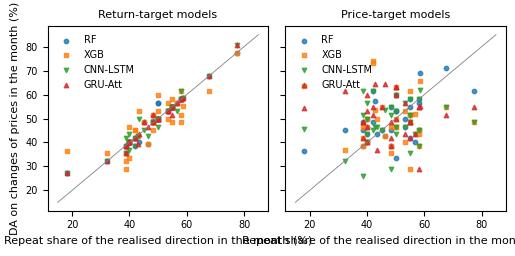

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 2.6), sharex=True, sharey=True)
for ax, group, title in zip(axes, ('return', 'price'), ('Return-target models', 'Price-target models')):
    for name, mk in zip([m for m in LEARNED if m.endswith(group)], 'osv^'):
        ax.scatter(t_month['repeat share (%)'], t_month[name], s=10, marker=mk, label=name.rsplit('-', 1)[0], alpha=0.8)
    lim = [15, 85]
    ax.plot(lim, lim, color='grey', lw=0.6)
    ax.set_title(title)
    ax.set_xlabel('Repeat share of the realised direction in the month (%)')
    ax.legend(frameon=False, loc='upper left')
axes[0].set_ylabel('DA on changes of prices in the month (%)')
fig.tight_layout()
fig.savefig(FIG / 'fig2_monthly_changes.png')
fig.savefig(FIG / 'fig2_monthly_changes.pdf')
plt.show()

## 6. Trading evaluation

Position for day *t*+1: long when $\hat P_{t+1}>P_t$, short when $\hat P_{t+1}<P_t$, flat
otherwise. Daily excess return $s_t\,(R_{t+1}-r^f_{t+1}) - c\,|s_t-s_{t-1}|$ with $R$ the simple
return and $c$ the cost per side (a reversal costs $2c$, the first trade $c$). Sharpe ratios
are annualised with $\sqrt{365}$; standard errors follow Lo (2002) under i.i.d. returns.
Buy-and-hold pays the cost once. The random walk never trades and is omitted.

In [22]:
rf_t = df['rf'].values[i_te]
R_simple = P_t1 / P_t - 1
ex_mkt = R_simple - rf_t


def strategy(yhat, cost_bp):
    s = np.sign(yhat - P_t)
    trades = np.abs(np.diff(np.concatenate([[0.0], s])))
    cost = cost_bp / 1e4 * trades
    return s, s * ex_mkt - cost, s * R_simple - cost, trades


def sharpe(x):
    return np.sqrt(ANN) * x.mean() / x.std(ddof=1)


def sharpe_se(x):
    sr = x.mean() / x.std(ddof=1)
    return np.sqrt(ANN) * np.sqrt((1 + 0.5 * sr ** 2) / len(x))


rows, net = [], {}
for cost in COSTS_BP:
    bh = ex_mkt.copy()
    bh[0] -= cost / 1e4
    bh_total = R_simple.copy()
    bh_total[0] -= cost / 1e4
    net[('Buy & Hold', cost)] = bh
    rows.append({'model': 'Buy & Hold', 'cost (bp)': cost, 'Sharpe': sharpe(bh), 'SE': sharpe_se(bh),
                 'cumulative return (%)': 100 * (np.prod(1 + bh_total) - 1),
                 'trades per year': ANN / T, 'long share (%)': 100.0})
    for name in LEARNED:
        s, x, x_total, trades = strategy(forecasts[name], cost)
        net[(name, cost)] = x
        rows.append({'model': name, 'cost (bp)': cost, 'Sharpe': sharpe(x), 'SE': sharpe_se(x),
                     'cumulative return (%)': 100 * (np.prod(1 + x_total) - 1),
                     'trades per year': ANN * np.mean(trades > 0), 'long share (%)': 100 * np.mean(s > 0)})
t_trade = pd.DataFrame(rows)
t_trade['95% CI low'] = t_trade['Sharpe'] - 1.96 * t_trade['SE']
t_trade['95% CI high'] = t_trade['Sharpe'] + 1.96 * t_trade['SE']
t_trade.to_csv(RES / 't06_trading.csv', index=False)
print(f'Average T-bill rate over the test period: {100 * ((1 + rf_t).prod() ** (ANN / T) - 1):.2f}% a year')
print(t_trade.to_string(index=False, float_format=lambda v: f'{v:,.3f}'))

Average T-bill rate over the test period: 4.28% a year
          model  cost (bp)  Sharpe    SE  cumulative return (%)  trades per year  long share (%)  95% CI low  95% CI high
     Buy & Hold          0   0.501 0.591                 61.529            0.349         100.000      -0.657        1.659
       RF-price          0   0.511 0.591                 31.387           21.286           7.457      -0.647        1.669
      XGB-price          0   1.043 0.591                172.535           25.473          11.663      -0.115        2.202
 CNN-LSTM-price          0  -0.232 0.591                -52.472            3.489           3.442      -1.390        0.926
  GRU-Att-price          0  -0.184 0.591                -49.318            3.489           2.772      -1.341        0.974
      RF-return          0   0.878 0.591                138.361           55.134          49.618      -0.281        2.036
     XGB-return          0   0.310 0.591                 11.708          125.970          5

### Is any strategy better than buy-and-hold?

* **Sharpe difference**: test of equal Sharpe ratios of Ledoit and Wolf (2008), HAC standard
  error by the delta method and two-sided *p* from the studentised circular block bootstrap
  (block length 10).
* **Market timing**: Henriksson-Merton (1981) regression
  $x_t = \alpha + \beta\,e_t + \gamma \max(0,-e_t) + u_t$ of the strategy excess return
  $x_t$ on the buy-and-hold excess return $e_t$; $\gamma>0$ indicates timing ability.
  Newey-West standard errors, one-sided *p*.

In [23]:
def _moments(x, y):
    return x.mean(), y.mean(), (x ** 2).mean(), (y ** 2).mean()


def sr_diff(x, y):
    mx, my, gx, gy = _moments(x, y)
    return mx / np.sqrt(gx - mx ** 2) - my / np.sqrt(gy - my ** 2)


def hac_cov(V, lag=NW_LAG):
    S = V.T @ V / len(V)
    for k in range(1, lag + 1):
        G = V[k:].T @ V[:-k] / len(V)
        S += (1 - k / (lag + 1)) * (G + G.T)
    return S


def sr_diff_se(x, y, psi=None):
    mx, my, gx, gy = _moments(x, y)
    grad = np.array([gx / (gx - mx ** 2) ** 1.5, -gy / (gy - my ** 2) ** 1.5,
                     -mx / (2 * (gx - mx ** 2) ** 1.5), my / (2 * (gy - my ** 2) ** 1.5)])
    if psi is None:
        psi = hac_cov(np.column_stack([x - mx, y - my, x ** 2 - gx, y ** 2 - gy]))
    return np.sqrt(grad @ psi @ grad / len(x))


def lw_test(x, y, B=N_BOOT, b=BLOCK, seed=42):
    """Ledoit-Wolf (2008): annualised difference, its HAC SE, bootstrap p (two-sided)."""
    n = len(x)
    d, se = sr_diff(x, y), sr_diff_se(x, y)
    rng = np.random.default_rng(seed)
    nb = n // b
    hits = 0
    for _ in range(B):
        idx = ((rng.integers(0, n, size=nb)[:, None] + np.arange(b)[None, :]) % n).ravel()
        xs, ys_ = x[idx], y[idx]
        mx, my, gx, gy = _moments(xs, ys_)
        V = np.column_stack([xs - mx, ys_ - my, xs ** 2 - gx, ys_ ** 2 - gy])
        blocks = V.reshape(nb, b, 4).sum(axis=1) / np.sqrt(b)
        se_b = sr_diff_se(xs, ys_, blocks.T @ blocks / nb)
        hits += abs(sr_diff(xs, ys_) - d) / se_b >= abs(d) / se
    return np.sqrt(ANN) * d, np.sqrt(ANN) * se, (hits + 1) / (B + 1)


def hm_test(x, position):
    if np.all(position == position[0]):          # never changes position: the regression is degenerate
        return np.nan, np.nan, np.nan
    X = sm.add_constant(np.column_stack([ex_mkt, np.maximum(0.0, -ex_mkt)]))
    res = sm.OLS(x, X).fit(cov_type='HAC', cov_kwds={'maxlags': NW_LAG})
    return res.params[2], res.tvalues[2], stats.norm.sf(res.tvalues[2])


rows = []
for cost in (0, 50):
    for name in LEARNED:
        x = net[(name, cost)]
        d, se, p = lw_test(x, net[('Buy & Hold', cost)])
        g, t_g, p_g = hm_test(x, np.sign(forecasts[name] - P_t))
        rows.append({'model': name, 'cost (bp)': cost, 'Sharpe minus buy-and-hold': d, 'SE': se,
                     'p (bootstrap)': p, 'HM gamma': g, 'HM t': t_g, 'HM p': p_g})
t_sr = pd.DataFrame(rows)
for col in ['p (bootstrap)', 'HM p']:
    t_sr[col + ', Holm (16)'] = multipletests(t_sr[col].fillna(1.0).values, method='holm')[1]
t_sr.to_csv(RES / 't07_sharpe_tests.csv', index=False)

rows = []
series = {'Buy & Hold': R_simple - np.r_[50 / 1e4, np.zeros(T - 1)]}
for name in LEARNED:
    series[name] = strategy(forecasts[name], 50)[2]
for name, x in series.items():
    row = {'model': name}
    for y in sorted(set(test_dates.year)):
        sel = np.asarray(test_dates.year == y)
        row[f'return {y} (%)'] = 100 * (np.prod(1 + x[sel]) - 1)
    rows.append(row)
t_year = pd.DataFrame(rows)
t_year.to_csv(RES / 't06b_returns_by_year.csv', index=False)
print(t_year.to_string(index=False, float_format=lambda v: f'{v:,.1f}'))
print(t_sr.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

          model  return 2024 (%)  return 2025 (%)  return 2026 (%)
     Buy & Hold            112.7             -6.0            -19.6
       RF-price            -28.9            -10.7             12.9
      XGB-price             -3.5            -10.7             53.6
 CNN-LSTM-price            -53.6            -10.7              4.5
  GRU-Att-price            -50.5            -10.7              4.5
      RF-return            -13.4            -44.7              2.2
     XGB-return            -80.6            -54.1            -66.6
CNN-LSTM-return            -29.8            -24.5            -20.4
 GRU-Att-return             59.5             24.0            -35.2
          model  cost (bp)  Sharpe minus buy-and-hold     SE  p (bootstrap)  HM gamma    HM t   HM p  p (bootstrap), Holm (16)  HM p, Holm (16)
       RF-price          0                     0.0108 1.0647         0.9910    0.2517  1.4329 0.0759                    1.0000           0.7595
      XGB-price          0                

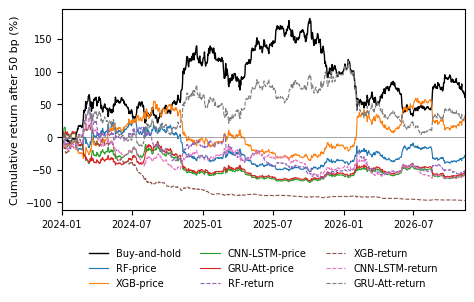

In [24]:
fig, ax = plt.subplots(figsize=(FIG_W, 2.6))
cost = 50
ax.plot(test_dates, 100 * (np.cumprod(1 + R_simple - np.r_[cost / 1e4, np.zeros(T - 1)]) - 1),
        color='black', lw=1.0, label='Buy-and-hold')
cmap = plt.get_cmap('tab10')
for k, name in enumerate(LEARNED):
    _, _, x_total, _ = strategy(forecasts[name], cost)
    ax.plot(test_dates, 100 * (np.cumprod(1 + x_total) - 1), lw=0.8, color=cmap(k),
            ls='-' if name.endswith('price') else '--', label=name)
ax.set_ylabel('Cumulative return after 50 bp (%)')
ax.xaxis.set_major_locator(matplotlib.dates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter('%Y-%m'))
ax.set_xlim(test_dates[0], test_dates[-1])
ax.axhline(0, color='grey', lw=0.5)
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15), frameon=False)
fig.savefig(FIG / 'fig3_cumulative_50bp.png')
fig.savefig(FIG / 'fig3_cumulative_50bp.pdf')
plt.show()

## 7. Seed dispersion

The tables above use the forecast averaged over the seeds. Here every seed is evaluated on
its own; XGBoost is deterministic and appears once.

In [25]:
rows = []
for name in LEARNED:
    for seed, yhat in forecasts_seed[name].items():
        rhat = implied_return(yhat)
        loss = (r_t1 - rhat) ** 2
        dm, dm_p = dm_hln(loss, loss_rw)
        da, z, p, _ = pt_test(dP, np.sign(yhat - P_t))
        rows.append({'model': name, 'seed': seed, 'RMSE ($)': np.sqrt(np.mean((P_t1 - yhat) ** 2)),
                     'OOS R2 (%)': 100 * (1 - loss.sum() / loss_rw.sum()), 'DM': dm, 'DM p': dm_p,
                     'DA signal (%)': da, 'PT p signal': p,
                     'Sharpe at 50 bp': sharpe(strategy(yhat, 50)[1])})
        if name.startswith('XGB'):
            break
t_seed = pd.DataFrame(rows)
t_seed.to_csv(RES / 't08_seeds.csv', index=False)
print(t_seed.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

          model  seed    RMSE ($)   OOS R2 (%)      DM   DM p  DA signal (%)  PT p signal  Sharpe at 50 bp
       RF-price    42 26,355.0983 -17,270.3294 10.2605 0.0000        51.6252       0.0115          -0.2156
       RF-price   123 26,473.8748 -17,474.0931 10.2677 0.0000        51.7208       0.0094          -0.1675
       RF-price   456 25,996.6667 -16,648.0289 10.2010 0.0000        53.1549       0.0004           0.5093
      XGB-price    42 27,313.4105 -19,001.7145 10.3544 0.0000        52.3901       0.0065           0.5081
 CNN-LSTM-price    42 25,998.2943 -17,292.6060 12.4140 0.0000        50.4780       0.1272          -0.1543
 CNN-LSTM-price   123 24,494.6082 -14,954.4816 12.6500 0.0000        50.0000       0.4117          -0.4137
 CNN-LSTM-price   456 23,623.0683 -13,519.8373 11.4733 0.0000        50.4780       0.2130          -0.3073
  GRU-Att-price    42 26,438.2600 -18,734.9163 13.0738 0.0000        50.4780       0.1185          -0.1529
  GRU-Att-price   123 31,110.4369 -27

## 8. Deep models trained for 100 epochs

Early stopping on the validation year selected between 1 and 6 epochs. To check that the
conclusions do not depend on this short training, each deep model is refitted with its
selected learning rate and batch size for 100 epochs, the setting of the earlier version of
this study, and evaluated in the same way. The first row of each pair repeats the reported
model.

In [26]:
EPOCHS_LONG = 3 if FAST else 100


def summary(yhat):
    rhat = implied_return(yhat)
    loss = (r_t1 - rhat) ** 2
    dm, dm_p = dm_hln(loss, loss_rw)
    _, cw_p = clark_west(r_t1, rhat)
    da_c, _, p_c, _ = pt_test(np.sign(np.diff(P_t1)), sign_change(np.log(yhat)))
    da_s, _, p_s, _ = pt_test(dP, np.sign(yhat - P_t))
    hits, _, p_st = sign_test(dP, np.sign(yhat - P_t))
    return {'RMSE ($)': np.sqrt(np.mean((P_t1 - yhat) ** 2)),
            'OOS R2 (%)': 100 * (1 - loss.sum() / loss_rw.sum()), 'DM': dm, 'DM p': dm_p, 'CW p': cw_p,
            'DA changes (%)': da_c, 'PT p changes': p_c, 'DA signal (%)': da_s, 'PT p signal': p_s,
            'correct days signal': hits, 'sign test p signal': p_st,
            'Fisher p signal': fisher_p(dP, np.sign(yhat - P_t)),
            'long share (%)': 100 * np.mean(yhat > P_t), 'long days': int(np.sum(yhat > P_t)),
            'long days with P_t below the 2017-2023 high': int(np.sum((yhat > P_t) & (P_t < cap))),
            'mean implied return (%)': 100 * rhat.mean(),
            'Sharpe at 50 bp': sharpe(strategy(yhat, 50)[1]),
            **{k: v for k, v in three_measures(yhat).items()
               if k in ('DA changes of returns (%)', 'PT z changes of returns', 'days changes of prices',
                        'days changes of returns', 'forecast change in the direction of the last return (%)')}}


rows, forecasts_long = [], {}
for arch_name, target in DL:
    name = f'{arch_name}-{target}'
    tun = t_dl_tuning[t_dl_tuning['model'] == name]
    best = tun.loc[tun['validation MSE (standardised)'].idxmin()]
    lr, batch = float(best['learning rate']), int(best['batch size'])
    rows.append({'model': name, 'epochs': int(best['best epoch']), **summary(forecasts[name])})
    preds, t0 = [], time.time()
    for seed in SEEDS:
        set_seeds(seed)
        w = WIN[target]
        m = build(arch_name, lr, w['trva'].shape[2])
        m.fit(w['trva'], ys(target, r_trva), epochs=EPOCHS_LONG, batch_size=batch, verbose=0)
        pred = y_scalers[target].inverse_transform(m.predict(w['te'], verbose=0)).ravel().astype(np.float64)
        preds.append(to_price(pred, target, i_te))
    forecasts_long[name] = np.mean(preds, axis=0)
    assert np.all(np.isfinite(forecasts_long[name])) and np.all(forecasts_long[name] > 0), name
    rows.append({'model': name, 'epochs': EPOCHS_LONG, **summary(forecasts_long[name])})
    print(f'{name}: {EPOCHS_LONG} epochs, {time.time() - t0:.0f}s for {len(SEEDS)} seeds')
t_ep = pd.DataFrame(rows)
t_ep.to_csv(RES / 't10_dl_epochs.csv', index=False)
pd.DataFrame(forecasts_long, index=test_dates).to_csv(LOCAL / 'forecasts_test_price_dl_long.csv')
print(t_ep.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

CNN-LSTM-price: 100 epochs, 230s for 3 seeds


GRU-Att-price: 100 epochs, 282s for 3 seeds


CNN-LSTM-return: 100 epochs, 195s for 3 seeds


GRU-Att-return: 100 epochs, 275s for 3 seeds
          model  epochs    RMSE ($)   OOS R2 (%)      DM   DM p   CW p  DA changes (%)  PT p changes  DA signal (%)  PT p signal  correct days signal  sign test p signal  Fisher p signal  long share (%)  long days  long days with P_t below the 2017-2023 high  mean implied return (%)  Sharpe at 50 bp  days changes of prices  DA changes of returns (%)  PT z changes of returns  days changes of returns  forecast change in the direction of the last return (%)
 CNN-LSTM-price       3 24,679.0330 -15,127.5688 12.1370 0.0000 0.1926         48.3254        0.8607        50.0956       0.3716                  524              0.4877           0.4374          3.4417         36                                           36                 -25.6536          -0.3036                    1045                    71.7703                  14.0775                     1045                                                  64.6890
 CNN-LSTM-price     100 21,774.7193 -

## 9. Return targets with the level features

The return-target models above read the 13 stationary features. Here the same four
models are tuned and refitted with the return target on the 19 features of the feature
file, which include price levels above their training range on most test days
(Section 2), and evaluated in the same way.

In [27]:
level_ret, t0 = {}, time.time()
X = X_all
lv = [val_mse(fit_rf('return', d, leaf, 42, i_tr, X).predict(X[i_va]), 'return') for d, leaf in RF_GRID]
depth, leaf = RF_GRID[int(np.argmin(lv))]
level_ret['RF-return'] = np.mean([to_price(fit_rf('return', depth, leaf, sd, i_trva, X).predict(X[i_te]), 'return', i_te)
                                  for sd in SEEDS], axis=0)
lv = [val_mse(fit_xgb('return', *g, i_tr, X).predict(X[i_va]), 'return') for g in XGB_GRID]
g = XGB_GRID[int(np.argmin(lv))]
level_ret['XGB-return'] = to_price(fit_xgb('return', *g, i_trva, X).predict(X[i_te]), 'return', i_te)
w = WIN['price']                       # windows of the 19 features
for arch_name in ('CNN-LSTM', 'GRU-Att'):
    best = None
    for lr, batch in DL_GRID:
        set_seeds(42)
        m = build(arch_name, lr, w['tr'].shape[2])
        h = m.fit(w['tr'], ys('return', r_tr), validation_data=(w['va'], ys('return', i_va)),
                  epochs=MAX_EPOCHS, batch_size=batch, verbose=0,
                  callbacks=[EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)])
        vl = h.history['val_loss']
        if best is None or min(vl) < best[0]:
            best = (min(vl), lr, batch, int(np.argmin(vl)) + 1)
    _, lr, batch, n_ep = best
    preds = []
    for sd in SEEDS:
        set_seeds(sd)
        m = build(arch_name, lr, w['trva'].shape[2])
        m.fit(w['trva'], ys('return', r_trva), epochs=n_ep, batch_size=batch, verbose=0)
        pred = y_scalers['return'].inverse_transform(m.predict(w['te'], verbose=0)).ravel().astype(np.float64)
        preds.append(to_price(pred, 'return', i_te))
    level_ret[f'{arch_name}-return'] = np.mean(preds, axis=0)
rows = []
for name, yhat in level_ret.items():
    assert np.all(np.isfinite(yhat)) and np.all(yhat > 0), name
    rows.append({'model': name, 'features': 'level (19)', **summary(yhat)})
    rows.append({'model': name, 'features': 'stationary (13)', **summary(forecasts[name])})
t_lev = pd.DataFrame(rows)
t_lev.to_csv(RES / 't12_return_targets_level_features.csv', index=False)
print(f'{time.time() - t0:.0f}s')
print(t_lev.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

178s
          model        features   RMSE ($)  OOS R2 (%)      DM   DM p   CW p  DA changes (%)  PT p changes  DA signal (%)  PT p signal  correct days signal  sign test p signal  Fisher p signal  long share (%)  long days  long days with P_t below the 2017-2023 high  mean implied return (%)  Sharpe at 50 bp  days changes of prices  DA changes of returns (%)  PT z changes of returns  days changes of returns  forecast change in the direction of the last return (%)
      RF-return      level (19) 1,967.8366     -3.7104  2.0511 0.0405 0.1757         48.8995        0.7621        50.7648       0.0622                  531              0.3214           0.0859          3.3461         35                                           35                  -0.5164           0.0875                    1045                    43.3493                  -4.2872                     1045                                                  98.3732
      RF-return stationary (13) 1,920.4230      0.9721 -0.7256 0.

## 9b. Linear baselines and monthly refits

Two checks of the design. (i) Linear baselines for the return target: a ridge regression on
the 13 stationary features, with the penalty chosen on the validation year, and a regression
on the last return alone. (ii) The reported models are fitted once on 2017-2023; here
RF-return and XGB-return keep their selected configuration but are refitted at the start of
each calendar month of the test period on all days whose target is already known.

In [28]:
from sklearn.linear_model import Ridge, LinearRegression
extra, t0 = {}, time.time()
Xs = X_BY_TARGET['return']
ALPHAS = [10.0 ** k for k in range(-1, 7)]
lv = [val_mse(Ridge(alpha=a).fit(Xs[i_tr], TARGETS['return'][i_tr]).predict(Xs[i_va]), 'return') for a in ALPHAS]
alpha = ALPHAS[int(np.argmin(lv))]
extra[f'Ridge-return (alpha={alpha:g})'] = to_price(Ridge(alpha=alpha).fit(Xs[i_trva], TARGETS['return'][i_trva]).predict(Xs[i_te]), 'return', i_te)
j_ret = STAT_FEATURES.index('log_return')
ar = LinearRegression().fit(Xs[i_trva][:, [j_ret]], TARGETS['return'][i_trva])
extra['AR(1)-return'] = to_price(ar.predict(Xs[i_te][:, [j_ret]]), 'return', i_te)

sel = {d['model']: dict(kv.strip().split('=') for kv in d['selected'].split(',')) for d in fit_info}
months = pd.PeriodIndex(test_dates, freq='M')
starts_m = [int(np.flatnonzero(months == m)[0]) for m in months.unique()]
bounds = list(zip(starts_m, starts_m[1:] + [T]))
rf_cfg, xgb_cfg = sel['RF-return'], sel['XGB-return']
pred_rf, pred_xgb = np.zeros((len(SEEDS), T)), np.zeros(T)
for k0, k1 in bounds:
    rows_fit = np.concatenate([i_trva, i_te[:k0]])        # targets of these days are known at the close of day k0
    for q, sd in enumerate(SEEDS):
        pred_rf[q, k0:k1] = fit_rf('return', int(rf_cfg['max_depth']), int(rf_cfg['min_samples_leaf']), sd,
                                   rows_fit, Xs).predict(Xs[i_te[k0:k1]])
    pred_xgb[k0:k1] = fit_xgb('return', float(xgb_cfg['learning_rate']), int(xgb_cfg['max_depth']),
                              int(xgb_cfg['n_estimators']), rows_fit, Xs).predict(Xs[i_te[k0:k1]])
extra['RF-return, monthly refit'] = np.mean([to_price(pr, 'return', i_te) for pr in pred_rf], axis=0)
extra['XGB-return, monthly refit'] = to_price(pred_xgb, 'return', i_te)
rows = [{'model': name, **summary(yhat)} for name, yhat in extra.items()]
for name in ('RF-return', 'XGB-return'):
    rows.append({'model': name + ', fitted once', **summary(forecasts[name])})
t_extra = pd.DataFrame(rows)
t_extra.insert(1, 'refits', [1, 1, len(bounds), len(bounds), 1, 1])
t_extra.to_csv(RES / 't13_baselines_refits.csv', index=False)
print(f'{time.time() - t0:.0f}s')
print(t_extra.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

44s
                      model  refits   RMSE ($)  OOS R2 (%)      DM   DM p   CW p  DA changes (%)  PT p changes  DA signal (%)  PT p signal  correct days signal  sign test p signal  Fisher p signal  long share (%)  long days  long days with P_t below the 2017-2023 high  mean implied return (%)  Sharpe at 50 bp  days changes of prices  DA changes of returns (%)  PT z changes of returns  days changes of returns  forecast change in the direction of the last return (%)
Ridge-return (alpha=100000)       1 1,923.8892     -0.0892  0.2533 0.8001 0.2325         48.9952        0.7421        50.0956          NaN                  524              0.4877              NaN        100.0000       1046                                          340                   0.1443           0.4970                    1045                    37.4163                  -8.2242                     1045                                                  99.8086
               AR(1)-return       1 1,922.8519      0.0663

The price-target tree ensembles are also refitted at the start of each month of the test
period, on all days whose target is known, with the configuration selected on the validation
year. Their forecasts can then follow the price into its new range with a delay.

In [29]:
t0 = time.time()
Xp = X_BY_TARGET['price']
rf_cfg, xgb_cfg = sel['RF-price'], sel['XGB-price']
pred_rf, pred_xgb = np.zeros((len(SEEDS), T)), np.zeros(T)
for k0, k1 in bounds:
    rows_fit = np.concatenate([i_trva, i_te[:k0]])
    for q, sd in enumerate(SEEDS):
        pred_rf[q, k0:k1] = fit_rf('price', int(rf_cfg['max_depth']), int(rf_cfg['min_samples_leaf']), sd,
                                   rows_fit, Xp).predict(Xp[i_te[k0:k1]])
    pred_xgb[k0:k1] = fit_xgb('price', float(xgb_cfg['learning_rate']), int(xgb_cfg['max_depth']),
                              int(xgb_cfg['n_estimators']), rows_fit, Xp).predict(Xp[i_te[k0:k1]])
refit_price = {'RF-price, monthly refit': pred_rf.mean(axis=0), 'XGB-price, monthly refit': pred_xgb}
rows = []
for name, yhat in refit_price.items():
    assert np.all(np.isfinite(yhat)) and np.all(yhat > 0), name
    rows.append({'model': name, 'refits': len(bounds), **summary(yhat), 'highest forecast ($)': yhat.max(),
                 'PT p changes of returns': three_measures(yhat)['PT p changes of returns']})
for name in ('RF-price', 'XGB-price'):
    rows.append({'model': name + ', fitted once', 'refits': 1, **summary(forecasts[name]),
                 'highest forecast ($)': forecasts[name].max(),
                 'PT p changes of returns': three_measures(forecasts[name])['PT p changes of returns']})
t_refit = pd.DataFrame(rows)
t_refit.to_csv(RES / 't13b_price_targets_monthly_refit.csv', index=False)
pd.DataFrame({**extra, **refit_price, **{f'{k}, level features': v for k, v in level_ret.items()}},
             index=test_dates).to_csv(LOCAL / 'forecasts_test_price_extra.csv')
print(f'{time.time() - t0:.0f}s')
print(t_refit.T.to_string(header=False, float_format=lambda v: f'{v:,.4f}'))

66s
model                                                    RF-price, monthly refit  XGB-price, monthly refit  RF-price, fitted once  XGB-price, fitted once
refits                                                                        35                        35                      1                       1
RMSE ($)                                                              4,516.6974                4,744.2098            26,274.1598             27,313.4105
OOS R2 (%)                                                             -385.7965                 -433.2760           -17,125.5382            -19,001.7145
DM                                                                        2.5207                    2.7905                10.2423                 10.3544
DM p                                                                      0.0119                    0.0054                 0.0000                  0.0000
CW p                                                                    

## 10. Monte Carlo: forecasters with known skill, and forecasts without skill

Daily log returns $r_{t}$ are i.i.d. Gaussian. The forecaster's prediction $\hat r_{t+1}$ has
correlation $\rho$ with $r_{t+1}$ and standard deviation $s$ (relative to $r$); it is the
conditional mean, the best forecast given its information, when $s=\rho$. The price forecast
is $\hat P_{t+1}=P_t e^{\hat r_{t+1}}$.

* The traded signal is right with probability $\tfrac12+\arcsin(\rho)/\pi$.
* The change between consecutive price forecasts, $r_t+\hat r_{t+1}-\hat r_t$, has correlation
  $c=\rho s/\sqrt{1-2\rho s+2s^2}$ with $r_{t+1}$, so the accuracy on changes of prices is
  $\tfrac12+\arcsin(c)/\pi$; for $s=\rho$, $c=\rho^2$.
* The change between consecutive return forecasts has correlation $\rho$ with
  $r_{t+1}-r_t$, so the accuracy on changes of returns is $\tfrac12+\arcsin(\rho)/\pi$.

Part (a) checks these expressions and the rejection rate of the one-sided 5% PT test over a
test period of the length used here. Part (b) leaves the assumptions: a forecast with a mean
different from zero (for which the accuracy of the traded signal is
$\Phi_2(m,0;\rho)+\Phi_2(-m,0;\rho)$, with $m$ the mean in forecast standard deviations and
$\Phi_2$ the bivariate normal distribution function), a forecast with a persistent
uninformative component, and returns with a persistent conditional mean forecast by that
mean. Part (c) scores price forecasts without skill on changes of returns, with Gaussian and
with Student $t$ returns: a constant price, the lagged price, momentum and moving averages.

In [30]:
# ---- Monte Carlo: forecasters with known skill, and forecasts without skill -------
from scipy.stats import multivariate_normal

def measures(eps, rhat):
    """eps[:, j]: return of day j; rhat[:, j]: its forecast. Boolean arrays (actual, predicted) under the
    three definitions over the last T days."""
    up = eps[:, 1:] > 0
    sig = rhat[:, 1:] > 0
    chg = (eps[:, :-1] + rhat[:, 1:] - rhat[:, :-1]) > 0          # log change between consecutive price forecasts
    d_up = (eps[:, 1:] - eps[:, :-1]) > 0
    d_hat = (rhat[:, 1:] - rhat[:, :-1]) > 0
    return {'signal': (up, sig), 'changes of prices': (up, chg), 'changes of returns': (d_up, d_hat)}


def mc(draw, seed, reps=None, crit=None, keep=False):
    """Mean accuracy (%), its Monte Carlo standard error and the rejection rate of the one-sided 5% PT test.
    crit: critical values simulated without skill, for size-adjusted rejection rates; keep: return such values."""
    reps = reps or MC_REPS
    rng = np.random.default_rng(seed)
    acc = {k: [] for k in ('signal', 'changes of prices', 'changes of returns')}
    zs = {k: [] for k in acc}
    same, done = [], 0
    while done < reps:
        m = min(MC_CHUNK, reps - done)
        eps, rhat = draw(rng, m)
        ms = measures(eps, rhat)
        same.append(((eps[:, :-1] > 0) == ms['changes of prices'][1]).mean(1))
        for k, (a, f) in ms.items():
            hit, z = pt_rows(a, f)
            acc[k].append(hit)
            zs[k].append(z)
        done += m
    out = {'forecast change in the direction of the last return, simulated (%)': 100 * np.concatenate(same).mean()}
    for k in acc:
        hit, z = np.concatenate(acc[k]), np.concatenate(zs[k])
        out[f'DA {k}, simulated (%)'] = 100 * hit.mean()
        out[f'DA {k}, standard error'] = 100 * hit.std() / np.sqrt(reps)
        out[f'PT rejections {k} (%)'] = 100 * np.mean(np.nan_to_num(z, nan=-9) > Z95)
        if keep:
            out[f'critical value at 5% {k}, simulated without skill'] = np.nanquantile(z, 0.95)
        if crit is not None:
            out[f'size-adjusted rejections {k} (%)'] = 100 * np.mean(np.nan_to_num(z, nan=-9) > crit[k])
    return out


def level_tied(rho_b, s_b):
    """Price forecast K exp(b): b has correlation rho_b with the next return and dispersion s_b and is independent
    across days; K is the starting price. Its implied return is b minus the log price relative to K."""
    def draw(rng, m):
        eps = rng.standard_normal((m, T + 1))
        b = s_b * (rho_b * eps + np.sqrt(1 - rho_b ** 2) * rng.standard_normal((m, T + 1)))
        return eps, b - (np.cumsum(eps, 1) - eps)
    return draw


def gaussian_forecaster(rho, s, bias=0.0):
    """(A1)-(A2): forecast with correlation rho, dispersion s and a mean of `bias` forecast standard deviations."""
    def draw(rng, m):
        eps = rng.standard_normal((m, T + 1))
        z = rho * eps + np.sqrt(1 - rho ** 2) * rng.standard_normal((m, T + 1))
        return eps, s * (z + bias)
    return draw


def persistent_component(rho_b, s_b, s_a, phi):
    """Forecast = uninformative AR(1) part a + informative part b independent across days."""
    def draw(rng, m):
        eps = rng.standard_normal((m, T + 1))
        b = s_b * (rho_b * eps + np.sqrt(1 - rho_b ** 2) * rng.standard_normal((m, T + 1)))
        a = np.empty((m, T + 1))
        a[:, 0] = s_a * rng.standard_normal(m)
        shock = np.sqrt(1 - phi ** 2) * s_a * rng.standard_normal((m, T + 1))
        for t in range(1, T + 1):
            a[:, t] = phi * a[:, t - 1] + shock[:, t]
        return eps, a + b
    return draw


def persistent_mean(rho, phi):
    """Returns with a persistent conditional mean mu (AR(1), variance rho^2), forecast by mu itself."""
    def draw(rng, m):
        mu = np.empty((m, T + 1))
        mu[:, 0] = rho * rng.standard_normal(m)
        shock = rho * np.sqrt(1 - phi ** 2) * rng.standard_normal((m, T + 1))
        for t in range(1, T + 1):
            mu[:, t] = phi * mu[:, t - 1] + shock[:, t]
        return mu + np.sqrt(1 - rho ** 2) * rng.standard_normal((m, T + 1)), mu
    return draw


def da_signal_theory(rho, bias=0.0):
    """Accuracy of the traded signal (%) for a Gaussian forecast whose mean is `bias` forecast standard deviations."""
    if bias == 0:
        return 50 + 100 * np.arcsin(rho) / np.pi
    bvn = multivariate_normal(mean=[0, 0], cov=[[1, rho], [rho, 1]])
    return 100 * (bvn.cdf([bias, 0]) + bvn.cdf([-bias, 0]))


n80 = lambda da: np.inf if da <= 50 else ((Z95 + Z80) / (2 * (da / 100 - 0.5))) ** 2

# (a) Gaussian forecasters independent across days
cases = [(0.0, 0.1, 'no skill')] + [(r, r, 'calibrated') for r in (0.02, 0.05, 0.1, 0.2, 0.3, 0.5)]
cases += [(r, m * r, lab) for r in (0.05, 0.1) for m, lab in ((0.5, 'shrunk (s = rho/2)'), (2.0, 'inflated (s = 2 rho)'))]
cases += [(r, 1.0, 'unit variance (s = 1)') for r in (0.05, 0.1)]
cases += [(0.1, s_, f'large dispersion (s = {s_:g})') for s_ in (5.0, 10.0)]
rows = []
t0 = time.time()
KEYS3 = ('signal', 'changes of prices', 'changes of returns')
CRIT = None                                    # critical values of the PT statistic simulated without skill (first case)
for k, (rho, s, label) in enumerate(cases):
    th_s, th_c = theory_da(rho, s)
    kappa = (1 - rho * s) / np.sqrt(1 - 2 * rho * s + 2 * s ** 2)
    res = mc(gaussian_forecaster(rho, s), seed=1000 + k, crit=CRIT, keep=CRIT is None)
    if CRIT is None:
        assert rho == 0
        CRIT = {key: res[f'critical value at 5% {key}, simulated without skill'] for key in KEYS3}
        res.update({f'size-adjusted rejections {key} (%)': 5.0 for key in KEYS3})
    rows.append({'forecaster': label, 'rho': rho, 's': s, 'DA signal, theory (%)': th_s,
                 'DA changes of prices, theory (%)': th_c, 'DA changes of returns, theory (%)': th_s,
                 'forecast change in the direction of the last return, theory (%)': 50 + 100 * np.arcsin(kappa) / np.pi,
                 **res,
                 'days for 80% power, signal': n80(th_s), 'days for 80% power, changes of prices': n80(th_c)})
t_mc = pd.DataFrame(rows)
t_mc.to_csv(RES / 't09_monte_carlo.csv', index=False)
print(f'{MC_REPS} replications of {T} days each ({time.time() - t0:.0f}s)')
print(t_mc.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))

100000 replications of 1046 days each (97s)
               forecaster    rho       s  DA signal, theory (%)  DA changes of prices, theory (%)  DA changes of returns, theory (%)  forecast change in the direction of the last return, theory (%)  forecast change in the direction of the last return, simulated (%)  DA signal, simulated (%)  DA signal, standard error  PT rejections signal (%)  critical value at 5% signal, simulated without skill  DA changes of prices, simulated (%)  DA changes of prices, standard error  PT rejections changes of prices (%)  critical value at 5% changes of prices, simulated without skill  DA changes of returns, simulated (%)  DA changes of returns, standard error  PT rejections changes of returns (%)  critical value at 5% changes of returns, simulated without skill  size-adjusted rejections signal (%)  size-adjusted rejections changes of prices (%)  size-adjusted rejections changes of returns (%)  days for 80% power, signal  days for 80% power, changes of price

In [31]:
# (b) forecasts with a bias, a persistent uninformative component or a persistent conditional mean
rows = []
for k, (rho_b, s_b, s_a, phi) in enumerate([(0.1, 5.0, 10.0, 0.999), (0.2, 5.0, 10.0, 0.999), (0.0, 5.0, 10.0, 0.999),
                                            (0.2, 0.5, 8.5, 0.999)]):
    rho_all = rho_b * s_b / np.sqrt(s_a ** 2 + s_b ** 2)
    c = rho_b * s_b / np.sqrt(1 - 2 * rho_b * s_b + 2 * s_b ** 2 + 2 * (1 - phi) * s_a ** 2)
    rows.append({'case': 'persistent component', 'rho of the informative part': rho_b, 's of the informative part': s_b,
                 's of the persistent part': s_a, 'phi': phi, 'bias (forecast sd)': 0.0, 'rho of the forecast': rho_all,
                 'DA signal, theory (%)': 50 + 100 * np.arcsin(rho_all) / np.pi,
                 'DA changes of prices, theory (%)': 50 + 100 * np.arcsin(c) / np.pi,
                 'DA changes of returns, theory (%)':
                     50 + 100 * np.arcsin(rho_b * s_b / np.sqrt(s_b ** 2 + (1 - phi) * s_a ** 2)) / np.pi,
                 'bound of Corollary 2 for the forecast (%)': 50 + 100 * np.arcsin(rho_all / np.sqrt(2 - rho_all ** 2)) / np.pi,
                 **mc(persistent_component(rho_b, s_b, s_a, phi), seed=2000 + k)})
for k, (rho, s, bias) in enumerate([(0.1, 0.1, 1.0), (0.1, 0.1, 2.0), (0.1, 1.0, 2.0), (0.0, 0.1, 2.0)]):
    rows.append({'case': 'biased forecast', 'rho of the informative part': rho, 's of the informative part': s,
                 's of the persistent part': 0.0, 'phi': np.nan, 'bias (forecast sd)': bias, 'rho of the forecast': rho,
                 'DA signal, theory (%)': da_signal_theory(rho, bias),
                 'DA changes of prices, theory (%)': theory_da(rho, s)[1],
                 'DA changes of returns, theory (%)': 50 + 100 * np.arcsin(rho) / np.pi,
                 'bound of Corollary 2 for the forecast (%)': 50 + 100 * np.arcsin(rho / np.sqrt(2 - rho ** 2)) / np.pi,
                 **mc(gaussian_forecaster(rho, s, bias), seed=2100 + k)})
for k, (rho, phi) in enumerate([(0.3, 0.98), (0.1, 0.98)]):
    rows.append({'case': 'persistent conditional mean', 'rho of the informative part': rho, 's of the informative part': rho,
                 's of the persistent part': 0.0, 'phi': phi, 'bias (forecast sd)': 0.0, 'rho of the forecast': rho,
                 'DA signal, theory (%)': 50 + 100 * np.arcsin(rho) / np.pi,
                 'DA changes of prices, theory (%)': 50 + 100 * np.arcsin(rho ** 2) / np.pi,
                 'DA changes of returns, theory (%)':
                     50 + 100 * np.arcsin(rho * np.sqrt(1 - phi) / np.sqrt(1 - rho ** 2 * phi)) / np.pi,
                 'bound of Corollary 2 for the forecast (%)': 50 + 100 * np.arcsin(rho / np.sqrt(2 - rho ** 2)) / np.pi,
                 **mc(persistent_mean(rho, phi), seed=2200 + k)})
for k, (rho_b, s_b) in enumerate([(0.0, 0.5), (0.0, 1.0), (0.1, 0.5), (0.2, 0.5), (0.2, 1.0)]):
    c_ret = (1 + 2 * rho_b * s_b) / np.sqrt(2 * (1 + 2 * rho_b * s_b + 2 * s_b ** 2))
    rows.append({'case': 'tied to a price level', 'rho of the informative part': rho_b, 's of the informative part': s_b,
                 's of the persistent part': 0.0, 'phi': np.nan, 'bias (forecast sd)': 0.0, 'rho of the forecast': np.nan,
                 'DA signal, theory (%)': np.nan,
                 'DA changes of prices, theory (%)': 50 + 100 * np.arcsin(rho_b / np.sqrt(2)) / np.pi,
                 'DA changes of returns, theory (%)': 50 + 100 * np.arcsin(c_ret) / np.pi,
                 'forecast change in the direction of the last return, theory (%)': 50 - 100 * np.arcsin(rho_b / np.sqrt(2)) / np.pi,
                 'bound of Corollary 2 for the forecast (%)': np.nan,
                 **mc(level_tied(rho_b, s_b), seed=2300 + k)})
t_pers = pd.DataFrame(rows)
t_pers.to_csv(RES / 't09b_persistent_forecaster.csv', index=False)
print(t_pers.T.to_string(header=False, float_format=lambda v: f'{v:,.4f}'))


# (c) price forecasts without skill, scored on changes of returns
def no_skill(kind, tdf=None, sd=None, ar=0.0, sv=False, shift=0.0):
    """Returns (Gaussian, or Student t with tdf degrees of freedom; independent across days unless ar or sv is set)
    and a price forecast that uses no information about the next return.
    ar: first-order autocorrelation of the returns; sv: stochastic volatility, the log variance being an AR(1)
    with coefficient 0.95 and innovations of standard deviation 0.3; shift: mean of the returns in standard deviations."""
    sd = sd or r_t1.std()
    W = 32                                                    # warm-up days, so that the 30-day average exists on every scored day

    def draw(rng, m):
        e = rng.standard_normal((m, T + W)) if tdf is None else rng.standard_t(tdf, size=(m, T + W))
        if ar:
            for j in range(1, T + W):
                e[:, j] = ar * e[:, j - 1] + np.sqrt(1 - ar ** 2) * e[:, j]
        if sv:
            h = 0.3 / np.sqrt(1 - 0.95 ** 2) * rng.standard_normal(m)
            xi = rng.standard_normal((m, T + W))
            for j in range(T + W):
                h = 0.95 * h + 0.3 * xi[:, j]
                e[:, j] *= np.exp(h / 2)
        e = sd * (e + shift)
        lp = np.cumsum(e, 1)                                  # log price at the close of each day
        if kind == 'Constant price':
            rhat = -(lp - e)                                  # log K - log P_t, up to a constant
        elif kind == 'Lagged price':
            rhat = -np.roll(e, 1, axis=1)                     # log P_{t-1} - log P_t = -r_t
        elif kind == 'Momentum':
            rhat = np.roll(e, 1, axis=1)
        else:                                                 # moving average of the last k closes
            k = int(kind.split()[-2])
            csum = np.cumsum(np.exp(lp), 1)
            ma = (csum[:, k:] - csum[:, :-k]) / k             # mean of closes j-k+1..j at column j-k
            ma = np.concatenate([np.full((m, k), np.nan), ma], axis=1)
            rhat = np.roll(np.log(ma) - lp, 1, axis=1)        # forecast of day j uses closes up to j-1
        return e[:, W - 1:], rhat[:, W - 1:]
    return draw


kinds = ['Constant price', 'Lagged price', 'Momentum', 'Moving average, 7 days', 'Moving average, 30 days']
theory = {'Constant price': 75.0, 'Lagged price': 100 * 2 / 3, 'Momentum': 100 / 3}
obs = t_three.set_index('forecast')
rows = []
for k, kind in enumerate(kinds):
    g = mc(no_skill(kind), seed=3000 + k)
    h = mc(no_skill(kind, tdf=3), seed=3100 + k)
    rows.append({'forecast': kind, 'theory (%)': theory.get(kind, np.nan),
                 'Gaussian returns: DA changes of returns (%)': g['DA changes of returns, simulated (%)'],
                 'Gaussian returns: PT rejections (%)': g['PT rejections changes of returns (%)'],
                 'Student t(3) returns: DA changes of returns (%)': h['DA changes of returns, simulated (%)'],
                 'Student t(3) returns: PT rejections (%)': h['PT rejections changes of returns (%)'],
                 'test period: DA changes of returns (%)': obs.loc[kind, 'DA changes of returns (%)'],
                 'test period: PT z': obs.loc[kind, 'PT z changes of returns']})
    if kind in theory:                          # the three forecasts of Proposition 4 under other return processes
        col = 'DA changes of returns, simulated (%)'
        rows[-1].update({
            'stochastic volatility: DA changes of returns (%)': mc(no_skill(kind, sv=True), seed=3200 + k)[col],
            'AR(1) returns, 0.1: DA changes of returns (%)': mc(no_skill(kind, ar=0.1), seed=3300 + k)[col],
            'AR(1) returns, -0.1: DA changes of returns (%)': mc(no_skill(kind, ar=-0.1), seed=3400 + k)[col],
            'P(r > 0) = 0.6: DA changes of returns (%)': mc(no_skill(kind, shift=stats.norm.ppf(0.6)), seed=3500 + k)[col],
            'P(r > 0) = 0.6: theory (%)': {'Constant price': 100 * (0.5 + 0.6 * 0.4)}.get(kind, theory[kind])})
t_noskill = pd.DataFrame(rows)
t_noskill.to_csv(RES / 't09c_no_skill_changes_of_returns.csv', index=False)
print(t_noskill.T.to_string(header=False, float_format=lambda v: f'{v:,.4f}'))

# the count of correct changes of a constant price forecast over a short sample: 70 or more of 89
rng = np.random.default_rng(3600)
e = rng.standard_normal((MC_REPS, 90))
cnt = (np.sign(e[:, 1:] - e[:, :-1]) == -np.sign(e[:, :-1])).sum(1)
t_win = pd.DataFrame([{'changes': 89, 'correct changes': 70, 'replications': MC_REPS,
                       'P(correct >= 70), simulated': np.mean(cnt >= 70),
                       'P(correct >= 70), binomial with probability 3/4': stats.binom.sf(69, 89, 0.75),
                       'mean of the count, simulated': cnt.mean(),
                       'variance of the count, simulated': cnt.var(), 'variance of the count, binomial': 89 * 0.75 * 0.25}])
t_win.to_csv(RES / 't09d_constant_price_window.csv', index=False)
print(t_win.T.to_string(header=False, float_format=lambda v: f'{v:,.4f}'))

case                                                                persistent component  persistent component  persistent component  persistent component  biased forecast  biased forecast  biased forecast  biased forecast  persistent conditional mean  persistent conditional mean  tied to a price level  tied to a price level  tied to a price level  tied to a price level  tied to a price level
rho of the informative part                                                       0.1000                0.2000                0.0000                0.2000           0.1000           0.1000           0.1000           0.0000                       0.3000                       0.1000                 0.0000                 0.0000                 0.1000                 0.2000                 0.2000
s of the informative part                                                         5.0000                5.0000                5.0000                0.5000           0.1000           0.1000           1.0000   

forecast                                          Constant price  Lagged price  Momentum  Moving average, 7 days  Moving average, 30 days
theory (%)                                               75.0000       66.6667   33.3333                     NaN                      NaN
Gaussian returns: DA changes of returns (%)              75.0001       66.6627   33.3299                 72.7130                  74.4719
Gaussian returns: PT rejections (%)                     100.0000      100.0000    0.0000                100.0000                 100.0000
Student t(3) returns: DA changes of returns (%)          75.0013       66.6570   33.3291                 71.2934                  73.8337
Student t(3) returns: PT rejections (%)                 100.0000      100.0000    0.0000                100.0000                 100.0000
test period: DA changes of returns (%)                   74.3541       65.6459   34.3541                 72.0574                  74.4498
test period: PT z                 

changes                                              89.0000
correct changes                                      70.0000
replications                                    100,000.0000
P(correct >= 70), simulated                           0.2228
P(correct >= 70), binomial with probability 3/4       0.2541
mean of the count, simulated                         66.7425
variance of the count, simulated                     12.9176
variance of the count, binomial                      16.6875


## 11. Positive control on the real test returns

The Monte Carlo assumes Gaussian returns. Here the realised daily log returns of the test
period are kept and a forecast with known skill is built from them:
$\hat r_{t+1} = \rho\,\sigma\,z_{t+1}$ with $z_{t+1} = \rho\,u_{t+1} + \sqrt{1-\rho^2}\,\eta_{t+1}$, where
$u$ is the standardised realised return, $\sigma$ its standard deviation and $\eta$ independent
Gaussian noise, so that the forecast has correlation $\rho$ with the realised return. It is not
a model, since it uses the realised return: it only checks whether each accuracy measure
detects a skill that is known to be there. Each draw also builds a forecast without skill
and with the same dispersion, $\rho\,\sigma\,\eta'_{t+1}$; the 95th percentile of its PT
statistics gives the critical value of the size-adjusted power. The first table keeps the
realised path; in the second, each draw also resamples the test returns in circular blocks.

In [32]:
# ---- positive control: a known skill injected into the realised returns -----------
sd_r = r_t1.std()
u = (r_t1 - r_t1.mean()) / sd_r
KEYS = ('signal', 'changes of prices', 'changes of returns')


def control(rho, s, seed, resample):
    """z statistics and accuracies of a forecast with correlation rho and dispersion s, and of a forecast
    without skill and with the same dispersion, on the realised path or on block-resampled paths."""
    rng = np.random.default_rng(seed)
    acc = {(k, w): [] for k in KEYS for w in ('skill', 'none')}
    zs = {kw: [] for kw in acc}
    corr, same, done = [], [], 0
    while done < MC_REPS:
        m = min(MC_CHUNK, MC_REPS - done)
        if resample:
            rb = r_t1[block_index(rng, T, m)]
            sb = rb.std(1, keepdims=True)
            ub = (rb - rb.mean(1, keepdims=True)) / sb
        else:
            rb, sb, ub = np.broadcast_to(r_t1, (m, T)), sd_r, u[None, :]
        eta, eta0 = rng.standard_normal((m, T)), rng.standard_normal((m, T))
        rhat = s * sb * (rho * ub + np.sqrt(1 - rho ** 2) * eta)
        corr.append(corr_rows(rhat, rb))
        for w, f in (('skill', rhat), ('none', s * sb * eta0)):
            ms = measures(rb, f)
            if w == 'skill':
                same.append(((rb[:, :-1] > 0) == ms['changes of prices'][1]).mean(1))
            for k, (a, p) in ms.items():
                hit, z = pt_rows(a, p)
                acc[(k, w)].append(hit)
                zs[(k, w)].append(z)
        done += m
    out = {'rho': rho, 's': s, 'mean realised correlation': np.concatenate(corr).mean(),
           'forecast change in the direction of the last return (%)': 100 * np.concatenate(same).mean()}
    for k in KEYS:
        z1 = np.nan_to_num(np.concatenate(zs[(k, 'skill')]), nan=-9)
        z0 = np.nan_to_num(np.concatenate(zs[(k, 'none')]), nan=-9)
        out.update({f'DA {k} (%)': 100 * np.concatenate(acc[(k, 'skill')]).mean(),
                    f'DA {k}, no skill (%)': 100 * np.concatenate(acc[(k, 'none')]).mean(),
                    f'PT rejections {k} (%)': 100 * np.mean(z1 > Z95),
                    f'PT rejections {k}, no skill (%)': 100 * np.mean(z0 > Z95),
                    f'size-adjusted power {k} (%)': 100 * np.mean(z1 > np.quantile(z0, 0.95))})
    return out


lam = lambda rho: rho / np.sqrt(1 - rho ** 2)
rows = []
t0 = time.time()
for k, rho in enumerate((0.02, 0.05, 0.1, 0.2)):
    th_s, th_c = theory_da(rho, rho)
    rows.append({**control(rho, rho, seed=700 + k, resample=False),
                 'DA signal, Gaussian theory (%)': th_s, 'DA changes of prices, Gaussian theory (%)': th_c,
                 'DA signal, expected on this path (%)': 100 * np.mean(stats.norm.cdf(np.sign(r_t1[1:]) * lam(rho) * u[1:]))})
t_pc = pd.DataFrame(rows)
t_pc.to_csv(RES / 't11_positive_control.csv', index=False)
print(f'{MC_REPS} noise draws over the {T - 1} forecast changes of the test period ({time.time() - t0:.0f}s); '
      f'repeat share of the realised direction: {Q_TEST:.2f}%')
print(t_pc.T.to_string(header=False, float_format=lambda v: f'{v:,.4f}'))

t0 = time.time()
t_pcb = pd.DataFrame([control(rho, rho, seed=800 + k, resample=True) for k, rho in enumerate((0.05, 0.1, 0.2))])
t_pcb.to_csv(RES / 't11b_positive_control_resampled.csv', index=False)
print(f'{MC_REPS} block-resampled paths, one noise draw each ({time.time() - t0:.0f}s)')
print(t_pcb.T.to_string(header=False, float_format=lambda v: f'{v:,.4f}'))

100000 noise draws over the 1045 forecast changes of the test period (43s); repeat share of the realised direction: 49.00%
rho                                                      0.0200  0.0500  0.1000  0.2000
s                                                        0.0200  0.0500  0.1000  0.2000
mean realised correlation                                0.0200  0.0500  0.0999  0.2001
forecast change in the direction of the last return (%) 98.3499 96.1885 92.9912 87.2868
DA signal (%)                                           50.5601 51.4169 52.8149 55.6337
DA signal, no skill (%)                                 50.0022 49.9953 50.0038 50.0106
PT rejections signal (%)                                 9.5970 22.5460 56.1280 97.6760
PT rejections signal, no skill (%)                       4.6990  4.7450  4.8840  4.8090
size-adjusted power signal (%)                          10.1010 23.2960 56.5230 97.7680
DA changes of prices (%)                                48.6733 48.7119 48.7864 49.78

100000 block-resampled paths, one noise draw each (42s)
rho                                                      0.0500  0.1000  0.2000
s                                                        0.0500  0.1000  0.2000
mean realised correlation                                0.0501  0.1001  0.1999
forecast change in the direction of the last return (%) 96.2022 93.0079 87.3196
DA signal (%)                                           51.4081 52.8297 55.6372
DA signal, no skill (%)                                 50.0069 49.9952 49.9994
PT rejections signal (%)                                23.0160 57.4040 97.8190
PT rejections signal, no skill (%)                       4.9740  4.8780  4.8710
size-adjusted power signal (%)                          23.0870 57.8690 97.8720
DA changes of prices (%)                                48.8122 48.9006 49.9147
DA changes of prices, no skill (%)                      48.7111 48.5120 48.5019
PT rejections changes of prices (%)                      0.6870 

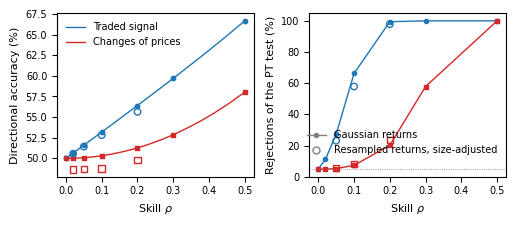

In [33]:
grid = np.linspace(0, 0.5, 101)
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 2.3))
cal = t_mc[t_mc['forecaster'].isin(['calibrated', 'no skill'])]
axes[0].plot(grid, [theory_da(r, r)[0] for r in grid], color='tab:blue', lw=1, label='Traded signal')
axes[0].plot(grid, [theory_da(r, r)[1] for r in grid], color='tab:red', lw=1, label='Changes of prices')
axes[0].scatter(cal['rho'], cal['DA signal, simulated (%)'], s=10, color='tab:blue')
axes[0].scatter(cal['rho'], cal['DA changes of prices, simulated (%)'], s=10, color='tab:red', marker='s')
axes[0].scatter(t_pc['rho'], t_pc['DA signal (%)'], s=22, facecolors='none', edgecolors='tab:blue')
axes[0].scatter(t_pc['rho'], t_pc['DA changes of prices (%)'], s=22, facecolors='none',
                edgecolors='tab:red', marker='s')
axes[0].set_xlabel(r'Skill $\rho$')
axes[0].set_ylabel('Directional accuracy (%)')
axes[0].legend(frameon=False)
axes[1].plot(cal['rho'], cal['PT rejections signal (%)'], 'o-', color='tab:blue', ms=3, lw=1)
axes[1].plot(cal['rho'], cal['PT rejections changes of prices (%)'], 's-', color='tab:red', ms=3, lw=1)
axes[1].scatter(t_pcb['rho'], t_pcb['size-adjusted power signal (%)'], s=22, facecolors='none', edgecolors='tab:blue')
axes[1].scatter(t_pcb['rho'], t_pcb['size-adjusted power changes of prices (%)'], s=22, facecolors='none', edgecolors='tab:red',
                marker='s')
axes[1].axhline(5, color='grey', lw=0.6, ls=':')
axes[1].set_xlabel(r'Skill $\rho$')
axes[1].set_ylabel('Rejections of the PT test (%)')
from matplotlib.lines import Line2D
axes[1].legend(handles=[Line2D([], [], color='grey', marker='o', ms=3, lw=1, label='Gaussian returns'),
                        Line2D([], [], color='grey', marker='o', ms=5, lw=0, markerfacecolor='none',
                               label='Resampled returns, size-adjusted')],
               frameon=False, loc='lower right', bbox_to_anchor=(1.0, 0.08))
fig.tight_layout()
fig.savefig(FIG / 'fig4_monte_carlo.png')
fig.savefig(FIG / 'fig4_monte_carlo.pdf')
plt.show()

## 12. Run record

In [34]:
manifest = {'notebook': 'bitcoin_prediction_benchmark_v19.ipynb', 'fast_mode': FAST,
            'run_finished_utc': pd.Timestamp.utcnow().isoformat(),
            'runtime_minutes': round((time.time() - T0_NOTEBOOK) / 60, 1),
            'design': {'train_end': TRAIN_END, 'validation_end': VAL_END, 'test_first': str(test_dates.min().date()),
                       'test_last': str(test_dates.max().date()), 'test_forecasts': T, 'seeds': SEEDS,
                       'lookback': LOOKBACK, 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'epochs_long': EPOCHS_LONG,
                       'dl_grid': DL_GRID, 'costs_bp': COSTS_BP, 'block': BLOCK, 'newey_west_lag': NW_LAG,
                       'bootstrap_draws': N_BOOT, 'mcs_draws': MCS_REPS, 'monte_carlo_replications': MC_REPS,
                       'resampled_paths': N_PATHS, 'level_simulation_paths': N_SIM, 'calibration_block_lengths': BLOCKS_CAL,
                       'tie_tolerance': TIE, 'correlation_bootstrap_draws': N_CI, 'dm_lags': DM_LAGS},
            'data_fingerprint': FINGERPRINT, 'versions': VERSIONS,
            'sources': {'prices': 'CoinMarketCap historical data exports (not redistributed)',
                        'risk_free': 'FRED TB3MS, 3-Month Treasury Bill Secondary Market Rate, monthly'},
            'outputs': sorted(p.name for p in list(RES.glob('*.csv')) + list(FIG.glob('*.png'))
                              + list(FIG.glob('*.pdf')))}
(RES / 'manifest_v19.json').write_text(json.dumps(manifest, indent=1, default=str))
print(json.dumps({k: manifest[k] for k in ('fast_mode', 'runtime_minutes', 'outputs')}, indent=1))

{
 "fast_mode": false,
 "runtime_minutes": 38.1,
 "outputs": [
  "fig1_price_target_forecasts.pdf",
  "fig1_price_target_forecasts.png",
  "fig2_monthly_changes.pdf",
  "fig2_monthly_changes.png",
  "fig3_cumulative_50bp.pdf",
  "fig3_cumulative_50bp.png",
  "fig4_monte_carlo.pdf",
  "fig4_monte_carlo.png",
  "t01_splits.csv",
  "t01b_stationarity.csv",
  "t01c_feature_range.csv",
  "t02a_xgb_validation.csv",
  "t02b_dl_validation.csv",
  "t03_selected_configurations.csv",
  "t04_accuracy.csv",
  "t04b_dm_lags.csv",
  "t05_direction.csv",
  "t05b_price_target_long_days.csv",
  "t05c_level_rule.csv",
  "t05d_level_rule_size.csv",
  "t05e_calibrated_tests.csv",
  "t05f_block_length.csv",
  "t06_trading.csv",
  "t06b_returns_by_year.csv",
  "t07_sharpe_tests.csv",
  "t08_seeds.csv",
  "t09_monte_carlo.csv",
  "t09b_persistent_forecaster.csv",
  "t09c_no_skill_changes_of_returns.csv",
  "t09d_constant_price_window.csv",
  "t10_dl_epochs.csv",
  "t11_positive_control.csv",
  "t11b_positive_